# EDA do Peter — por que o DTW atual rejeita todo SIM de um informante novo?

**Projeto Peter** · Reconhecimento de Libras com DTW sobre Canonical Skeleton v1 · WAICY

Este notebook é uma **EDA reproduzível** do matcher atual. Ele relê os templates e fixtures do repositório, reimplementa em Python/NumPy o mesmo cálculo de features e DTW do runtime TypeScript e mostra, com evidência, por que o sinal **SIM** de um informante não casa com o **SIM** de outro.

> **Escopo e restrições respeitadas**
> - Nenhum arquivo fora de `eda/` foi alterado.
> - `src/vision/pipeline/*.ts`, `src/core/config.ts` e thresholds **não** foram tocados.
> - Nenhum backend, banco de dados, FastAPI, PHP ou SQL foi criado.
> - Nenhuma rede neural foi proposta ou treinada. Com **18 amostras de 1 classe**, DTW continua sendo a escolha defensável; o EDA testa se o problema é o DTW ou a representação/normalização.
> - Os **24 templates v4** (só mão, **sem ombros**; 18 com 21 juntas e 6 com 42) são inventariados apenas para exclusão explícita: eles **não** são carregados pelo matcher atual e não entram em nenhum escore.

**Atribuição e licença do dataset:** LIBRAS-EQT-UECE Authors (2026), *LIBRAS-EQT-UECE*, licença **CC BY-NC 4.0**, DOI [10.5281/zenodo.21398895](https://doi.org/10.5281/zenodo.21398895), registro [Zenodo 21398895](https://zenodo.org/records/21398895). Os arquivos deste repositório são landmarks derivados (Canonical Skeleton v1), não o vídeo original. Uso não comercial, com atribuição.

**Convenção de leitura:** ao longo do notebook,
- **FATO confirmado** = número que saiu diretamente dos JSONs/fixtures ou foi reproduzido pelo código abaixo;
- **Hipótese a testar** = interpretação ou próximo experimento, ainda não validado em runtime.

## 0. Protocolo, dados e o que o `npm test` já reporta

O teste `src/vision/pipeline/libras-eqt-validation.test.ts` faz o seguinte:

1. Carrega os **18 templates dual** de `src/vision/templates/libras-eqt-dual-*.template.json` (todos `SIM`, `hand-shape-trajectory-v1`, split `train`, informantes 1–3).
2. Usa a fixture `libras-eqt-dual-evaluation.json`:
   - **validação** = INFORMANTE 4: 6 SIM + 18 negativos (CAIR, LUZ, JA);
   - **teste** = INFORMANTE 5: 6 SIM + 18 negativos (CAIR, LUZ, JA).
3. Ajusta threshold, `minMotion` e pesos **apenas na validação** (leave-one-informant-out), e depois avalia no teste intocado.
4. Reporta `LIBRAS-EQT_DUAL_REPORT` com três configurações: `default`, `historical-experimental` e `validation-selected`.

Este notebook reproduz o mesmo pipeline em Python e compara **linha a linha** com `libras-eqt-dual-evaluation-results.json`.

> **Limitação do dataset (citada no próprio relatório):** os rótulos de informante são **locais por item**; eles não garantem identidade física disjunta entre sinais diferentes. O split é por informante, nunca por amostra, para evitar leakage — mas isso não prova que I1–I3, I4 e I5 sejam pessoas fisicamente distintas em todos os itens.

## 1. Setup reprodutível

As células abaixo localizam o repositório a partir do diretório atual (ou da variável `PETER_REPO_ROOT`), carregam os JSONs e definem as constantes do runtime. As figuras são gravadas em `eda/figs/`.

In [1]:
# ===== 1.1 Imports, caminhos e estilo =====
import json
import os
import glob
import math
import re
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from sklearn.metrics import roc_curve, auc, roc_auc_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 170,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "figure.titlesize": 16,
})

PALETTE = {
    "SIM": "#0072B2",
    "NEG": "#D55E00",
    "validation": "#009E73",
    "test": "#CC79A7",
    "train": "#999999",
    "left": "#56B4E9",
    "right": "#E69F00",
    "both": "#666666",
    "shape": "#56B4E9",
    "trajectory": "#E69F00",
}


def find_repo_root() -> Path:
    """Encontra a raiz do Peter sem depender do diretório de execução."""
    candidates = []
    env = os.environ.get("PETER_REPO_ROOT")
    if env:
        candidates.append(Path(env).expanduser())
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    for base in candidates:
        if (base / "package.json").exists() and (base / "src" / "vision" / "pipeline").exists():
            return base.resolve()
    known = Path(r"C:\Users\henri\Documents\Henrique\Waicy\Peter-main")
    if (known / "package.json").exists():
        return known.resolve()
    raise FileNotFoundError("Repo do Peter não encontrado. Defina PETER_REPO_ROOT.")


REPO_ROOT = find_repo_root()
EDA_DIR = REPO_ROOT / "eda"
FIG_DIR = EDA_DIR / "figs"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TEMPLATE_DIR = REPO_ROOT / "src" / "vision" / "templates"
FIXTURE_DIR = REPO_ROOT / "src" / "vision" / "pipeline" / "fixtures"
FIXTURE_PATH = FIXTURE_DIR / "libras-eqt-dual-evaluation.json"
RESULTS_PATH = FIXTURE_DIR / "libras-eqt-dual-evaluation-results.json"

# Constantes copiadas do runtime (NÃO alteradas)
WINDOW_RATIO = 0.28
MAX_FRAMES = 16
MIN_VISIBILITY = 0.35
MIN_PALM_SCALE = 0.015
MIN_SHOULDER_SCALE = 0.04
WRIST_INDEX = 0
MIDDLE_MCP_INDEX = 9

CANONICAL_BODY_ORDER = [
    "head", "leftShoulder", "rightShoulder", "leftElbow", "rightElbow",
    "leftWrist", "rightWrist", "leftHip", "rightHip", "leftKnee",
    "rightKnee", "leftAnkle", "rightAnkle",
]
FINGERS = ["Thumb", "Index", "Middle", "Ring", "Pinky"]


def hand_joint_names(side: str):
    names = [f"{side}HandWrist"]
    for finger in FINGERS:
        for joint in range(1, 5):
            names.append(f"{side}{finger}{joint}")
    return names


LEFT_HAND_JOINTS = hand_joint_names("left")
RIGHT_HAND_JOINTS = hand_joint_names("right")

DEFAULT_CONFIG = {"name": "default", "threshold": 0.68, "minMotion": 0.018,
                  "handShape": 0.5, "handTrajectory": 0.5}
HISTORICAL_CONFIG = {"name": "historical-experimental", "threshold": 0.565,
                     "minMotion": 0.0, "handShape": 0.5, "handTrajectory": 0.5}
TUNING_WEIGHTS = [0.25, 0.5, 0.75]
TUNING_GATES = [0, 0.005, 0.01, 0.015, 0.018, 0.02, 0.025, 0.03, 0.04]
TUNING_THRESHOLDS = [round(0.5 + index * 0.01, 2) for index in range(46)]

for path in [FIXTURE_PATH, RESULTS_PATH, TEMPLATE_DIR, FIXTURE_DIR]:
    assert path.exists(), f"Arquivo/diretório ausente: {path}"

print("Repo:", REPO_ROOT)
print("Notebook/figuras:", EDA_DIR / "eda_peter.ipynb", "|", FIG_DIR)
print("Fixture:", FIXTURE_PATH.name, f"({FIXTURE_PATH.stat().st_size/1e6:.2f} MB)")
print("Results:", RESULTS_PATH.name, f"({RESULTS_PATH.stat().st_size/1e3:.1f} kB)")
print("Constantes: window=%.2f maxFrames=%d minVis=%.2f minPalm=%.3f minShoulder=%.2f" % (
    WINDOW_RATIO, MAX_FRAMES, MIN_VISIBILITY, MIN_PALM_SCALE, MIN_SHOULDER_SCALE))

Repo: C:\Users\henri\Documents\Henrique\Waicy\Peter-main
Notebook/figuras: C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\eda_peter.ipynb | C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\figs
Fixture: libras-eqt-dual-evaluation.json (3.43 MB)
Results: libras-eqt-dual-evaluation-results.json (43.1 kB)
Constantes: window=0.28 maxFrames=16 minVis=0.35 minPalm=0.015 minShoulder=0.04


## 2. Inventário e qualidade dos dados

### 2.1 Templates: dual vs. v4 órfãos

O matcher atual (`OfflineAnimationTemplateRepository`) carrega **somente** arquivos `libras-eqt-dual-*.template.json` cujo `metadata.featureRepresentation` seja `hand-shape-trajectory-v1`. Os templates `v4` **não** entram: eles **não têm nenhuma junta de ombro**, portanto `handTrajectory` (que depende do eixo dos ombros) é impossível.

> **Divergência com o briefing (dado real vs. premissa):** o texto de referência afirma que os 24 templates v4 têm 21 juntas. Nos arquivos reais, **18 têm 21 juntas** (INFORMANTE 1, 3 e 4) e **6 têm 42 juntas** (INFORMANTE 2, `activeHands = left,right`). Em **todos os 24**, a contagem de juntas de ombro é **zero**. Portanto a conclusão de exclusão não muda — mas o número de juntas **não é uniforme** e é reportado como está nos dados.

In [ ]:
# ===== 2.1 Carregar templates e fixtures =====
def read_json(path):
    with open(path, encoding="utf-8") as handle:
        return json.load(handle)


fixture = read_json(FIXTURE_PATH)
results = read_json(RESULTS_PATH)

dual_templates = []
for path in sorted(TEMPLATE_DIR.glob("libras-eqt-dual-*.template.json")):
    template = read_json(path)
    if template.get("metadata", {}).get("featureRepresentation") != "hand-shape-trajectory-v1":
        continue
    template["_fileName"] = path.name
    dual_templates.append(template)

template_rows = []
for template in dual_templates:
    metadata = template.get("metadata", {})
    template_rows.append({
        "id": template["id"],
        "gloss": template["gloss"],
        "informant": metadata.get("informant"),
        "split": metadata.get("split"),
        "n_frames": len(template["frames"]),
        "duration_s": template.get("duration"),
        "fps": template.get("fps"),
        "handCoverage_meta": float(metadata.get("handCoverage")),
        "shoulderCoverage_meta": float(metadata.get("shoulderCoverage")),
        "n_relevant_joints": len(template.get("relevantJoints", [])),
        "n_frame_joints": len(template["frames"][0]["joints"]),
        "featureRepresentation": metadata.get("featureRepresentation"),
        "fileName": template["_fileName"],
    })
templates_df = pd.DataFrame(template_rows)

# Inventário dos v4: metadados apenas, para exclusão explícita.
# O metadata dos v4 NÃO tem a chave "informant": ela é inferida de sourceEntry
# (ex.: ".../2_Sim/INFORMANTE 1/IMG_0745.npy").
v4_rows = []
for path in sorted(TEMPLATE_DIR.glob("libras-eqt-v4-*.template.json")):
    template = read_json(path)
    metadata = template.get("metadata", {})
    joints = template.get("relevantJoints", [])
    source_entry = metadata.get("sourceEntry") or ""
    match = re.search(r"INFORMANTE\s+(\d+)", source_entry)
    v4_rows.append({
        "id": template.get("id"),
        "gloss": template.get("gloss"),
        "informant": f"INFORMANTE {match.group(1)}" if match else None,
        "split": metadata.get("split"),
        "n_frames": len(template.get("frames", [])),
        "n_joints": len(joints),
        "has_shoulder": any(str(j).endswith("Shoulder") for j in joints),
        "activeHands": metadata.get("activeHands"),
        "comparisonNormalization": metadata.get("comparisonNormalization"),
        "fileName": path.name,
    })
v4_df = pd.DataFrame(v4_rows)

print("Templates dual carregados pelo matcher:", len(dual_templates))
print("\nContagem por gloss/informante/split:")
display(templates_df.groupby(["gloss", "split", "informant"]).size().rename("templates").to_frame())

print("\nTemplates v4 (NÃO carregados no runtime):", len(v4_df))
v4_summary = (v4_df.groupby(["informant", "n_joints", "activeHands", "split"])
              .size().rename("templates").to_frame().reset_index())
display(v4_summary)
print("v4 com ombro:", int(v4_df["has_shoulder"].sum()))
print("v4 por número de juntas:",
      v4_df.groupby("n_joints").size().to_dict())
print("v4 por informante:", v4_df.groupby("informant").size().to_dict())

# Asserções de inventário esperado
assert len(dual_templates) == 18
assert set(templates_df["gloss"]) == {"SIM"}
assert templates_df.groupby("informant").size().to_dict() == {
    "INFORMANTE 1": 6, "INFORMANTE 2": 6, "INFORMANTE 3": 6}
assert set(templates_df["split"]) == {"train"}
assert len(v4_df) == 24 and int(v4_df["has_shoulder"].sum()) == 0
assert v4_df["informant"].notna().all()
assert v4_df.groupby("informant").size().to_dict() == {
    "INFORMANTE 1": 6, "INFORMANTE 2": 6, "INFORMANTE 3": 6, "INFORMANTE 4": 6}
assert v4_df.groupby("n_joints").size().to_dict() == {21: 18, 42: 6}
print("\nOK: 18 templates dual (SIM, I1–I3 x6, train).")
print("OK: 24 v4 órfãos (I1–I4 x6), 0 com ombro; 18 com 21 juntas e 6 (I2) com 42 juntas.")

Templates dual carregados pelo matcher: 18

Contagem por gloss/informante/split:


templates
gloss split informant              
SIM   train INFORMANTE 1          6
            INFORMANTE 2          6
            INFORMANTE 3          6


Templates v4 (NÃO carregados no runtime): 24


,informant,n_joints,activeHands,split,templates
0,INFORMANTE 1,21,right,train,6
1,INFORMANTE 2,42,"left,right",train,6
2,INFORMANTE 3,21,right,train,6
3,INFORMANTE 4,21,right,train,6


v4 com ombro: 0
v4 por número de juntas: {21: 18, 42: 6}
v4 por informante: {'INFORMANTE 1': 6, 'INFORMANTE 2': 6, 'INFORMANTE 3': 6, 'INFORMANTE 4': 6}

OK: 18 templates dual (SIM, I1–I3 x6, train).
OK: 24 v4 órfãos (I1–I4 x6), 0 com ombro; 18 com 21 juntas e 6 (I2) com 42 juntas.


In [3]:
# ===== 2.2 Amostras: train (templates), validação (I4) e teste (I5) =====
extraction_df = pd.DataFrame(fixture["extractionSummary"])
extraction_df["truth"] = np.where(extraction_df["gloss"] == "SIM", "SIM", "NEG")

frames_by_id = {}
for split in ["validation", "test"]:
    for kind in ["positive", "negative"]:
        for sample in fixture[split][kind]:
            frames_by_id[sample["id"]] = sample["frames"]
for template in dual_templates:
    frames_by_id[template["id"]] = template["frames"]

missing = [sample_id for sample_id in extraction_df["id"] if sample_id not in frames_by_id]
assert not missing, f"Frames ausentes para: {missing}"

samples_df = extraction_df.copy()
samples_df["n_frames_stored"] = samples_df["id"].map(lambda sample_id: len(frames_by_id[sample_id]))
samples_df["source_frames_est"] = samples_df["duration"] * samples_df["sampleRate"]

print("Amostras no extractionSummary:", len(samples_df))
print("\nContagem por split/classe:")
display(samples_df.groupby(["split", "truth"]).size().rename("amostras").to_frame())

print("\nComprimento armazenado (frames), duração original e fps:")
summary = samples_df.groupby(["split", "truth"]).agg(
    n=("id", "size"),
    frames_stored=("n_frames_stored", "first"),
    duration_min=("duration", "min"),
    duration_mean=("duration", "mean"),
    duration_max=("duration", "max"),
    sampleRate=("sampleRate", "first"),
)
display(summary)

assert samples_df.groupby(["split", "truth"]).size().to_dict() == {
    ("train", "SIM"): 18,
    ("validation", "NEG"): 18,
    ("validation", "SIM"): 6,
    ("test", "NEG"): 18,
    ("test", "SIM"): 6,
}
assert samples_df["n_frames_stored"].eq(MAX_FRAMES).all()
print("\nOK: 18 train + (6 SIM + 18 NEG) validação + (6 SIM + 18 NEG) teste = 66 amostras.")
print("Todas as amostras armazenam 16 frames (resample uniforme para maxMatchFrames=16).")

Amostras no extractionSummary: 66

Contagem por split/classe:


amostras
split      truth          
test       NEG          18
           SIM           6
train      SIM          18
validation NEG          18
           SIM           6


Comprimento armazenado (frames), duração original e fps:


n  frames_stored  duration_min  duration_mean  duration_max  sampleRate
split      truth                                                                          
test       NEG    18             16         2.033          2.382         2.867          15
           SIM     6             16         2.767          3.278         4.733          15
train      SIM    18             16         1.900          2.515         3.567          15
validation NEG    18             16         2.067          2.502         3.333          15
           SIM     6             16         1.767          2.522         2.967          15


OK: 18 train + (6 SIM + 18 NEG) validação + (6 SIM + 18 NEG) teste = 66 amostras.
Todas as amostras armazenam 16 frames (resample uniforme para maxMatchFrames=16).


### 2.3 Cobertura de visibilidade, lateralidade e `motionEnergy`

Duas leituras são validadas aqui:

1. **`handCoverage` do metadata** não é “mão direita”: é a fração de frames com **alguma** mão visível (união esquerda ∪ direita). Recalculada nos 16 frames armazenados, ela se aproxima do metadata (o metadata foi medido nos frames originais, antes do resample).
2. **`shoulderCoverage=1.0`** deve bater exatamente: os ombros estão presentes em 100% dos frames armazenados.

Também calculamos a **lateralidade** (punho esquerdo vs. direito) porque ela se revela decisiva: os informantes não executam o mesmo SIM com a mesma mão, nem com a mesma quantidade de mãos.

In [4]:
# ===== 2.3 Features de qualidade (sem DTW) =====
def distance3(a, b):
    return math.hypot(a["x"] - b["x"], a["y"] - b["y"], a["z"] - b["z"])


def is_visible(point):
    return point.get("visibility", 1.0) >= MIN_VISIBILITY


def to_landmark_frame(frame):
    """Porta de canonicalSkeletonToLandmarkFrame (canonical-skeleton.ts)."""
    joints = frame["joints"]

    def point(name):
        value = joints.get(name)
        if value is None:
            return {"x": 0.0, "y": 0.0, "z": 0.0, "visibility": 0.0}
        return {
            "x": float(value["x"]),
            "y": float(value["y"]),
            "z": float(value["z"]),
            "visibility": float(value.get("visibility", 1.0)),
        }

    return {
        "timestamp": float(frame.get("timestamp", 0.0)),
        "body": [point(name) for name in CANONICAL_BODY_ORDER],
        "leftHand": [point(name) for name in LEFT_HAND_JOINTS],
        "rightHand": [point(name) for name in RIGHT_HAND_JOINTS],
    }


def landmark_travel(previous, current):
    total = 0.0
    count = 0
    for before, after in zip(previous, current):
        if is_visible(before) and is_visible(after):
            total += distance3(before, after)
            count += 1
    return total, count


def motion_energy(frames):
    """Porta de motionEnergy (feature-vector.ts): média da distância entre frames
    consecutivos para leftHand, rightHand e os dois punhos do corpo."""
    landmarks = [to_landmark_frame(frame) for frame in frames]
    if len(landmarks) < 2:
        return 0.0
    total = 0.0
    count = 0
    for previous, current in zip(landmarks[:-1], landmarks[1:]):
        pairs = [
            (previous["leftHand"], current["leftHand"]),
            (previous["rightHand"], current["rightHand"]),
            (previous["body"][5:7], current["body"][5:7]),
        ]
        for before, after in pairs:
            travel, observations = landmark_travel(before, after)
            total += travel
            count += observations
    return 0.0 if count == 0 else total / count


JOINT_GROUPS = {
    "head": ["head"],
    "ombros": ["leftShoulder", "rightShoulder"],
    "cotovelos": ["leftElbow", "rightElbow"],
    "punhos_corpo": ["leftWrist", "rightWrist"],
    "quadril": ["leftHip", "rightHip"],
    "mao_esquerda": LEFT_HAND_JOINTS,
    "mao_direita": RIGHT_HAND_JOINTS,
}


def group_frame_any(frames, joint_names):
    count = 0
    for frame in frames:
        if any(frame["joints"].get(name, {}).get("visibility", 0.0) >= MIN_VISIBILITY
               for name in joint_names):
            count += 1
    return count / len(frames)


def group_cell_coverage(frames, joint_names):
    visible = 0
    total = 0
    for frame in frames:
        for name in joint_names:
            total += 1
            if frame["joints"].get(name, {}).get("visibility", 0.0) >= MIN_VISIBILITY:
                visible += 1
    return visible / total if total else 0.0


def wrist_frame_fraction(frames, side):
    name = f"{side}HandWrist"
    return sum(frame["joints"].get(name, {}).get("visibility", 0.0) >= MIN_VISIBILITY
               for frame in frames) / len(frames)


coverage_rows = []
quality_rows = []
for _, row in samples_df.iterrows():
    frames = frames_by_id[row["id"]]
    quality_rows.append({
        "id": row["id"],
        "hand_union_calc": group_frame_any(frames, LEFT_HAND_JOINTS + RIGHT_HAND_JOINTS),
        "left_wrist_frac": wrist_frame_fraction(frames, "left"),
        "right_wrist_frac": wrist_frame_fraction(frames, "right"),
        "shoulder_any_calc": group_frame_any(frames, ["leftShoulder", "rightShoulder"]),
        "motionEnergy": motion_energy(frames),
    })
    for group, joint_names in JOINT_GROUPS.items():
        coverage_rows.append({
            "id": row["id"],
            "split": row["split"],
            "truth": row["truth"],
            "gloss": row["gloss"],
            "informant": row["informant"],
            "group": group,
            "frame_any": group_frame_any(frames, joint_names),
            "cell_coverage": group_cell_coverage(frames, joint_names),
        })

quality_df = pd.DataFrame(quality_rows)
samples_df = samples_df.merge(quality_df, on="id", how="left")
coverage_df = pd.DataFrame(coverage_rows)
samples_df["dominant_hand"] = np.where(
    samples_df["left_wrist_frac"] > samples_df["right_wrist_frac"], "LEFT", "RIGHT")

# --- Validação da leitura do metadata ---
comparison = samples_df[["handCoverage", "hand_union_calc"]].dropna()
correlation = comparison["handCoverage"].corr(comparison["hand_union_calc"])
mean_abs_diff = (comparison["handCoverage"] - comparison["hand_union_calc"]).abs().mean()
max_abs_diff = (comparison["handCoverage"] - comparison["hand_union_calc"]).abs().max()
shoulder_equal = np.allclose(samples_df["shoulderCoverage"], samples_df["shoulder_any_calc"], atol=1e-9)

print("handCoverage (metadata) vs união esquerda∪direita recalculada nos 16 frames:")
print(f"  correlação r = {correlation:.4f}")
print(f"  erro absoluto médio = {mean_abs_diff:.4f} | máximo = {max_abs_diff:.4f}")
print(f"  shoulderCoverage == recalculado? {shoulder_equal}")
display(samples_df[["id", "handCoverage", "hand_union_calc", "left_wrist_frac",
                    "right_wrist_frac", "shoulder_any_calc"]].head(6))

assert shoulder_equal
print("\nOK: shoulderCoverage=1.0 reproduzido exatamente; handCoverage é a cobertura de QUALQUER mão.")

# --- Cobertura por informante ---
coverage_pivot = coverage_df.groupby(["group", "informant"])["frame_any"].mean().unstack()
coverage_pivot = coverage_pivot.reindex(list(JOINT_GROUPS.keys()))
print("\nCobertura média por grupo de juntas e informante (fração de frames):")
display(coverage_pivot)

# --- Lateralidade ---
laterality_all = samples_df.groupby(["informant", "split"])[
    ["left_wrist_frac", "right_wrist_frac"]].mean()
laterality_sim = samples_df[samples_df["truth"] == "SIM"].groupby("informant")[
    ["left_wrist_frac", "right_wrist_frac"]].mean()
dominant_counts = samples_df[samples_df["truth"] == "SIM"].groupby(
    ["split", "informant", "dominant_hand"]).size().rename("n").to_frame()
print("\nLateralidade dos SIM (fração média de frames com punho visível):")
display(laterality_sim)
print("\nMão dominante nos SIM:")
display(dominant_counts)

# --- motionEnergy ---
motion_summary = samples_df.groupby(["split", "truth"])["motionEnergy"].agg(
    ["count", "mean", "median", "min", "max"])
print("\nmotionEnergy por split/classe:")
display(motion_summary)
print(f"Menor motionEnergy global: {samples_df['motionEnergy'].min():.4f}")
print(f"Amostras abaixo de minMotion=0.018: {(samples_df['motionEnergy'] < 0.018).sum()}")

assert (samples_df["motionEnergy"] >= 0.018).all()
print("\nFATO: nenhuma amostra é barrada pelo motion gate (0/66 abaixo de 0.018).")

handCoverage (metadata) vs união esquerda∪direita recalculada nos 16 frames:
  correlação r = 0.9911
  erro absoluto médio = 0.0246 | máximo = 0.1307
  shoulderCoverage == recalculado? True


,id,handCoverage,hand_union_calc,left_wrist_frac,right_wrist_frac,shoulder_any_calc
0,train-sim-train__SIM__INFORMANTE-1__IMG_0745,0.545,0.562,0.000,0.562,1.000
1,train-sim-train__SIM__INFORMANTE-1__IMG_0746,0.479,0.438,0.000,0.438,1.000
2,train-sim-train__SIM__INFORMANTE-1__IMG_0747,0.500,0.500,0.000,0.500,1.000
3,train-sim-train__SIM__INFORMANTE-1__IMG_0748,0.511,0.500,0.000,0.500,1.000
4,train-sim-train__SIM__INFORMANTE-1__IMG_0749,0.540,0.500,0.000,0.500,1.000
5,train-sim-train__SIM__INFORMANTE-1__IMG_0750,0.481,0.500,0.000,0.500,1.000



OK: shoulderCoverage=1.0 reproduzido exatamente; handCoverage é a cobertura de QUALQUER mão.

Cobertura média por grupo de juntas e informante (fração de frames):


informant,INFORMANTE 1,INFORMANTE 2,INFORMANTE 3,INFORMANTE 4,INFORMANTE 5
group,,,,,
head,1.000,1.000,1.000,1.000,1.000
ombros,1.000,1.000,1.000,1.000,1.000
cotovelos,1.000,1.000,1.000,1.000,1.000
punhos_corpo,0.990,1.000,1.000,0.901,1.000
quadril,0.438,0.990,1.000,0.818,1.000
mao_esquerda,0.000,0.969,0.000,0.062,0.930
mao_direita,0.500,0.667,0.677,0.432,0.810



Lateralidade dos SIM (fração média de frames com punho visível):


,left_wrist_frac,right_wrist_frac
informant,,
INFORMANTE 1,0.000,0.500
INFORMANTE 2,0.969,0.667
INFORMANTE 3,0.000,0.677
INFORMANTE 4,0.000,0.646
INFORMANTE 5,0.979,0.938



Mão dominante nos SIM:


n
split      informant    dominant_hand   
test       INFORMANTE 5 LEFT           5
                        RIGHT          1
train      INFORMANTE 1 RIGHT          6
           INFORMANTE 2 LEFT           6
           INFORMANTE 3 RIGHT          6
validation INFORMANTE 4 RIGHT          6


motionEnergy por split/classe:


count  mean  median   min   max
split      truth                                 
test       NEG       18 0.263   0.265 0.120 0.439
           SIM        6 0.185   0.182 0.116 0.237
train      SIM       18 0.440   0.465 0.188 0.675
validation NEG       18 0.752   0.728 0.491 1.212
           SIM        6 0.430   0.369 0.277 0.729

Menor motionEnergy global: 0.1159
Amostras abaixo de minMotion=0.018: 0

FATO: nenhuma amostra é barrada pelo motion gate (0/66 abaixo de 0.018).


### 2.4 Figura 1 — inventário, qualidade e lateralidade

A figura resume: templates por informante; amostras por split/classe; duração original; `motionEnergy` com o gate; cobertura por grupo de juntas; e a mão ativa nos SIM.

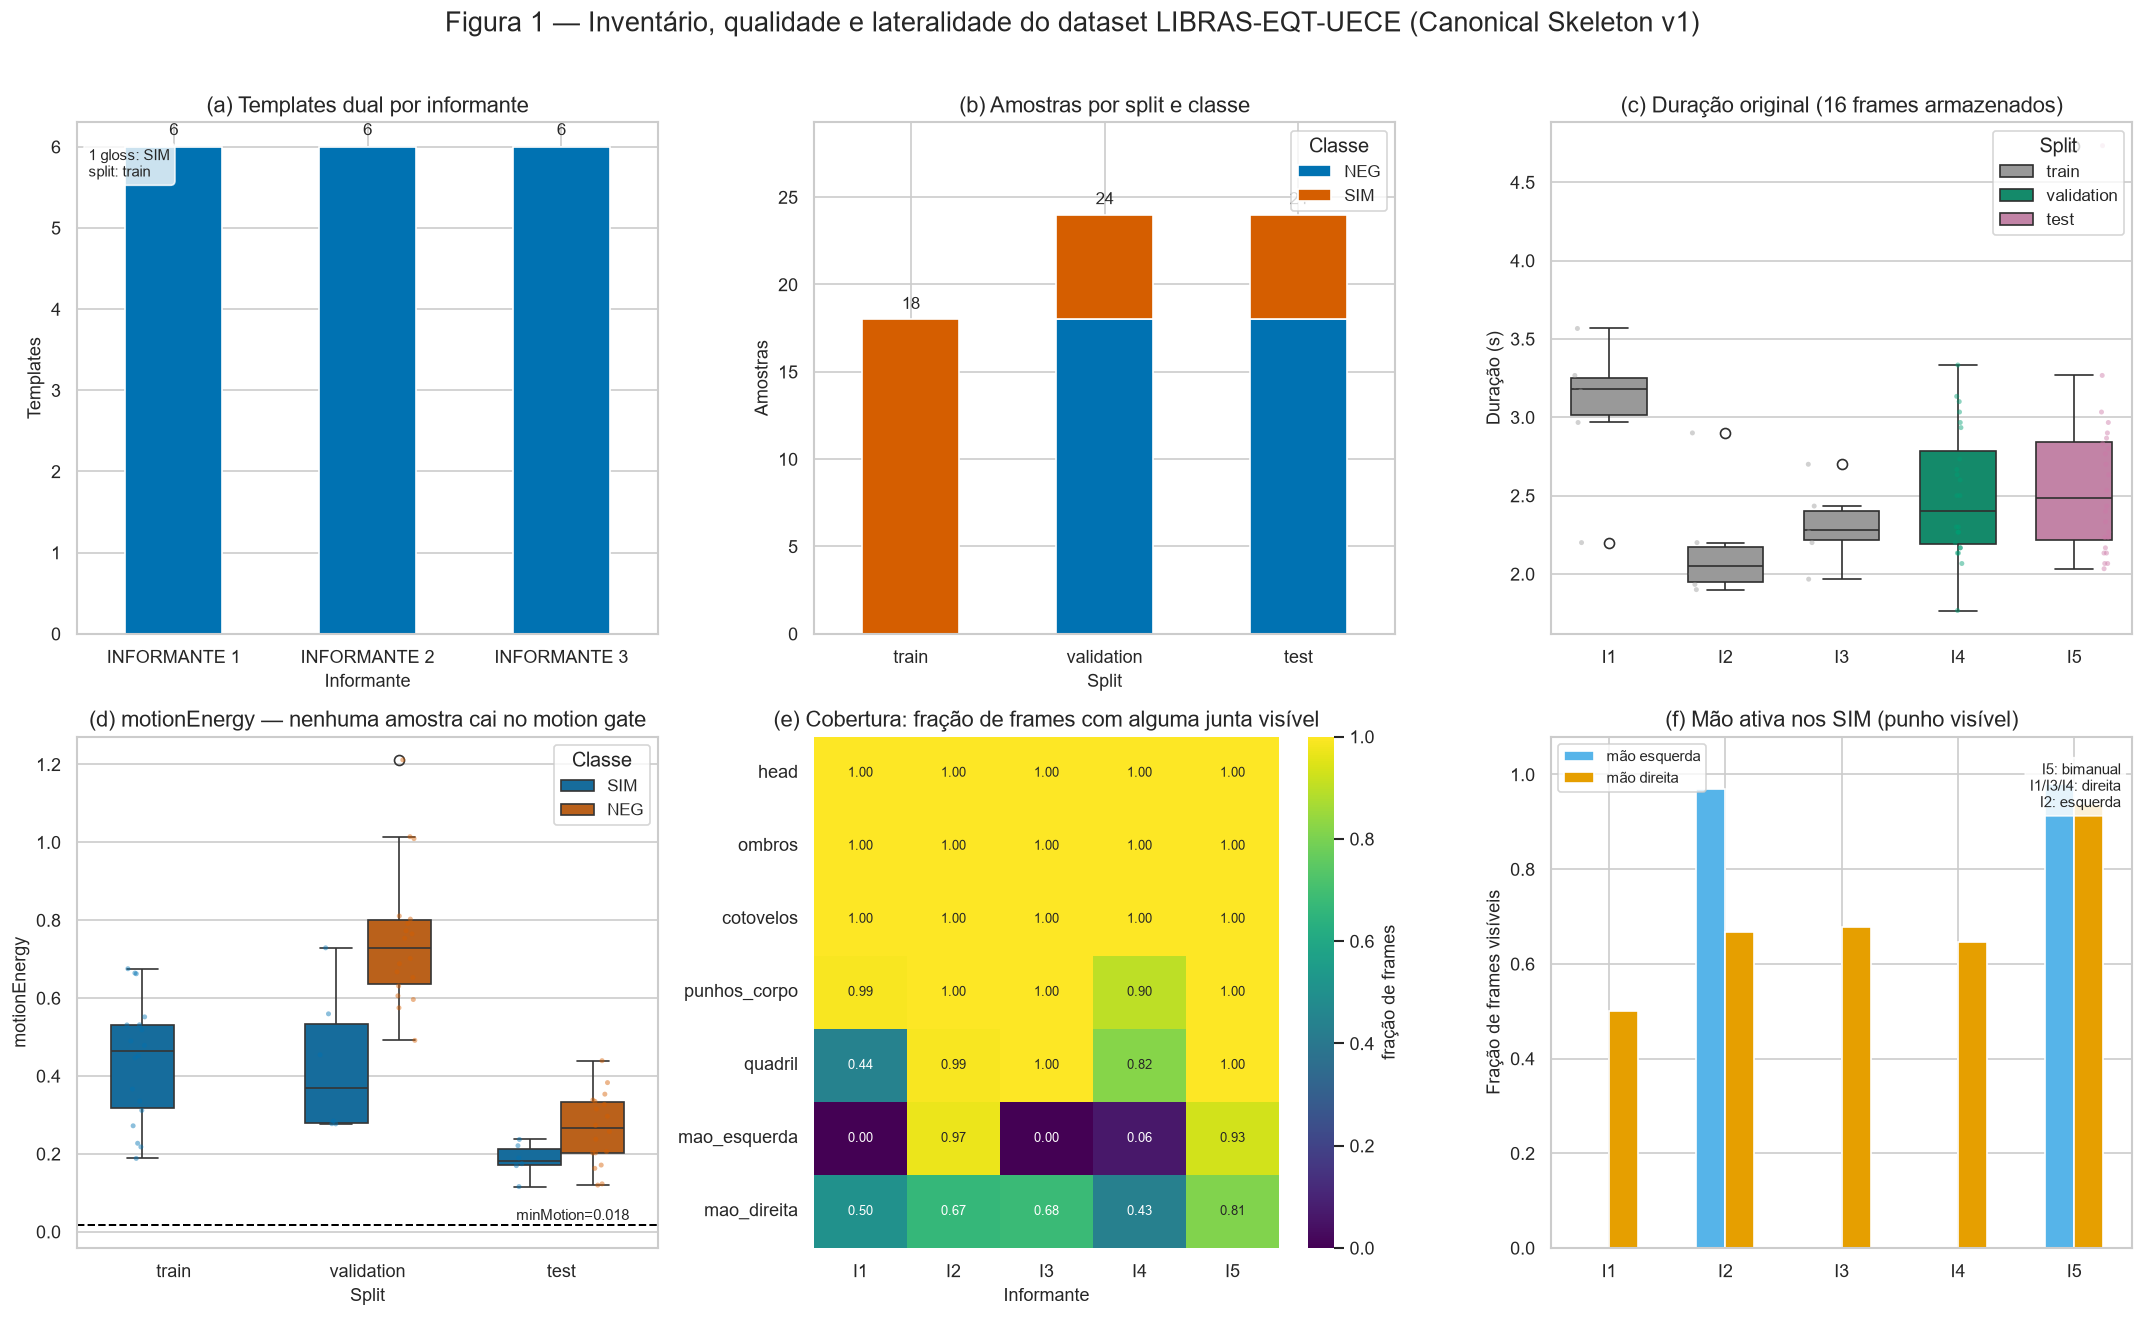

Figura salva em: C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\figs\fig_01_inventario.png


In [5]:
# ===== Figura 1: inventário e qualidade =====
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Figura 1 — Inventário, qualidade e lateralidade do dataset LIBRAS-EQT-UECE (Canonical Skeleton v1)",
             fontsize=16, y=0.995)

# (a) templates por informante
ax = axes[0, 0]
template_counts = templates_df.groupby(["informant", "gloss"]).size().unstack(fill_value=0)
template_counts.plot(kind="bar", ax=ax, color=PALETTE["SIM"], edgecolor="white", legend=False)
ax.set_title("(a) Templates dual por informante")
ax.set_xlabel("Informante")
ax.set_ylabel("Templates")
ax.tick_params(axis="x", rotation=0)
for index, value in enumerate(template_counts.sum(axis=1)):
    ax.text(index, value + 0.1, str(int(value)), ha="center", va="bottom", fontsize=10)
ax.text(0.02, 0.95, "1 gloss: SIM\nsplit: train", transform=ax.transAxes,
        va="top", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

# (b) amostras por split/classe
ax = axes[0, 1]
split_truth = samples_df.groupby(["split", "truth"]).size().unstack(fill_value=0)
split_truth = split_truth.reindex(["train", "validation", "test"]).fillna(0)
split_truth.plot(kind="bar", stacked=True, ax=ax,
                 color=[PALETTE["SIM"], PALETTE["NEG"]], edgecolor="white")
ax.set_title("(b) Amostras por split e classe")
ax.set_xlabel("Split")
ax.set_ylabel("Amostras")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, float(split_truth.sum(axis=1).max()) * 1.22)
for index, split in enumerate(split_truth.index):
    total = int(split_truth.loc[split].sum())
    ax.text(index, total + 0.4, str(total), ha="center", va="bottom", fontsize=10)
ax.legend(title="Classe", loc="upper right")

# (c) duração original
ax = axes[0, 2]
sns.boxplot(data=samples_df, x="informant", y="duration", hue="split",
            palette=[PALETTE["train"], PALETTE["validation"], PALETTE["test"]],
            ax=ax, width=0.65)
sns.stripplot(data=samples_df, x="informant", y="duration", hue="split",
              palette=[PALETTE["train"], PALETTE["validation"], PALETTE["test"]],
              dodge=True, size=3, alpha=0.45, ax=ax, legend=False)
ax.set_title("(c) Duração original (16 frames armazenados)")
ax.set_xlabel("")
ax.set_ylabel("Duração (s)")
ax.tick_params(axis="x", rotation=0)
ax.set_xticklabels([text.get_text().replace("INFORMANTE ", "I")
                    for text in ax.get_xticklabels()])
ax.legend(title="Split", loc="upper right")

# (d) motionEnergy
ax = axes[1, 0]
sns.boxplot(data=samples_df, x="split", y="motionEnergy", hue="truth",
            order=["train", "validation", "test"], hue_order=["SIM", "NEG"],
            palette=[PALETTE["SIM"], PALETTE["NEG"]], ax=ax, width=0.65)
sns.stripplot(data=samples_df, x="split", y="motionEnergy", hue="truth",
              order=["train", "validation", "test"], hue_order=["SIM", "NEG"],
              palette=[PALETTE["SIM"], PALETTE["NEG"]], dodge=True, size=3,
              alpha=0.45, ax=ax, legend=False)
ax.axhline(0.018, color="black", linestyle="--", linewidth=1.2)
ax.text(2.35, 0.022, "minMotion=0.018", ha="right", va="bottom", fontsize=9)
ax.set_title("(d) motionEnergy — nenhuma amostra cai no motion gate")
ax.set_xlabel("Split")
ax.set_ylabel("motionEnergy")
ax.legend(title="Classe", loc="upper right")

# (e) heatmap de cobertura
ax = axes[1, 1]
sns.heatmap(coverage_pivot, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1,
            ax=ax, cbar_kws={"label": "fração de frames"},
            annot_kws={"fontsize": 8})
ax.set_title("(e) Cobertura: fração de frames com alguma junta visível")
ax.set_xlabel("Informante")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)
ax.set_xticklabels([text.get_text().replace("INFORMANTE ", "I")
                    for text in ax.get_xticklabels()])

# (f) lateralidade dos SIM
ax = axes[1, 2]
laterality_sim.plot(kind="bar", ax=ax,
                    color=[PALETTE["left"], PALETTE["right"]], edgecolor="white")
ax.set_title("(f) Mão ativa nos SIM (punho visível)")
ax.set_xlabel("")
ax.set_ylabel("Fração de frames visíveis")
ax.set_ylim(0, 1.08)
ax.tick_params(axis="x", rotation=0)
ax.set_xticklabels([str(value).replace("INFORMANTE ", "I") for value in laterality_sim.index])
ax.legend(["mão esquerda", "mão direita"], loc="upper left", fontsize=9)
ax.text(0.98, 0.95, "I5: bimanual\nI1/I3/I4: direita\nI2: esquerda",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))

fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(FIG_DIR / "fig_01_inventario.png", bbox_inches="tight")
plt.show()
print("Figura salva em:", FIG_DIR / "fig_01_inventario.png")

**FATO confirmado (inventário e qualidade)**
- 18 templates dual, **um único gloss (SIM)**, 6 por informante (I1, I2, I3), todos em `train`, 16 frames, 55 juntas, `fps=15`.
- 24 templates v4 são órfãos (I1–I4 x6): **0 com ombro**, portanto não podem alimentar `handTrajectory`; ficaram fora de todos os escores. Eles **não** têm contagem uniforme de juntas: 18 têm 21 juntas e 6 (I2, bimanual) têm 42 — divergência em relação ao briefing, reportada como está nos dados.
- Fixtures: validação I4 = 6 SIM + 18 negativos; teste I5 = 6 SIM + 18 negativos; todas as 66 amostras têm 16 frames armazenados.
- `shoulderCoverage=1.0` bate exatamente; `handCoverage` do metadata é a **união** qualquer-mão (r=0,991; erro médio 0,025 nos 16 frames), não a mão direita.
- **Nenhuma** amostra é rejeitada por `motion_gate` (mínimo 0,1159 ≫ 0,018). Toda rejeição do teste é `below_threshold`.
- A lateralidade varia: I1/I3/I4 usam predominantemente a **direita**; I2 usa predominantemente a **esquerda**; I5 usa **as duas mãos** em quase todos os frames.

**Hipótese a testar (inventário e qualidade)**
- A diferença de execução (mão ativa e uso bimanual vs. unimanual) pode ser a causa dominante do baixo `handShape` cross-informant, mais do que ruído de MediaPipe. O teste está na seção 3.

## 3. Reprodução do matcher DTW em Python

Esta seção reimplementa, linha a linha, o que o runtime faz:

- `frameToHandShapeVector`: para cada mão, normaliza as 21 juntas pelo **punho** e pela distância **punho–middle MCP** (palma), com `visibility ≥ 0.35`; mão ausente vira 21×4 zeros.
- `frameToHandTrajectoryVector`: normaliza o **punho** pela origem e escala dos **ombros**; mão ausente vira 4 zeros.
- `sequenceToDualFeatureVectors`: concatena as duas mãos e reamostra uniformemente para `maxFrames=16`.
- `dtwDistance`: janela `max(1, |n−m|, ceil(max(n,m)·0.28))`, custo euclidiano, `pathCost/(n+m)`.
- `dtwSimilarity = 1/(1+distance)`.
- `combineFeatureScores`: média ponderada; se `handTrajectory` é `undefined`, o peso da trajetória vira 0.

Como há **um único gloss (SIM)**, o “melhor por gloss” do engine é simplesmente o **máximo sobre os 18 templates**, e o score combinado do melhor template é o `dtwScore` reportado. O `minScoreMargin=0.08` nunca entra: não existe runner-up de outro gloss.

In [6]:
# ===== 3.1 Porta NumPy/Python de feature-vector.ts + dtw.ts =====
def hand_shape_features(hand):
    """Porta de handShapeFeatures: 21 pontos x [x, y, z, 1]."""
    wrist = hand[WRIST_INDEX]
    middle_mcp = hand[MIDDLE_MCP_INDEX]
    scale = distance3(wrist, middle_mcp) if is_visible(wrist) and is_visible(middle_mcp) else 0.0
    if scale < MIN_PALM_SCALE:
        return [0.0] * (21 * 4)
    features = []
    for point in hand:
        if not is_visible(point):
            features.extend([0.0, 0.0, 0.0, 0.0])
        else:
            features.extend([
                (point["x"] - wrist["x"]) / scale,
                (point["y"] - wrist["y"]) / scale,
                (point["z"] - wrist["z"]) / scale,
                1.0,
            ])
    return features


def frame_to_hand_shape_vector(frame):
    return hand_shape_features(frame["leftHand"]) + hand_shape_features(frame["rightHand"])


def shoulder_reference(frame):
    body = frame["body"]
    left_index, right_index = (1, 2) if len(body) == 13 else (11, 12)
    left = body[left_index]
    right = body[right_index]
    if not is_visible(left) or not is_visible(right):
        return None
    scale = distance3(left, right)
    if scale < MIN_SHOULDER_SCALE:
        return None
    origin = {
        "x": (left["x"] + right["x"]) / 2.0,
        "y": (left["y"] + right["y"]) / 2.0,
        "z": (left["z"] + right["z"]) / 2.0,
    }
    return origin, scale


def hand_trajectory_features(hand, origin, scale):
    wrist = hand[WRIST_INDEX]
    if not is_visible(wrist):
        return [0.0, 0.0, 0.0, 0.0]
    return [
        (wrist["x"] - origin["x"]) / scale,
        (wrist["y"] - origin["y"]) / scale,
        (wrist["z"] - origin["z"]) / scale,
        1.0,
    ]


def frame_to_hand_trajectory_vector(frame):
    reference = shoulder_reference(frame)
    if reference is None:
        return None
    origin, scale = reference
    return (hand_trajectory_features(frame["leftHand"], origin, scale)
            + hand_trajectory_features(frame["rightHand"], origin, scale))


def js_round(value):
    """Math.round do JS: arredonda .5 para +infinito."""
    return math.floor(value + 0.5)


def resample_vectors(vectors, max_frames=MAX_FRAMES):
    if not vectors or max_frames < 1:
        return []
    if len(vectors) <= max_frames:
        return [list(vector) for vector in vectors]
    last_index = len(vectors) - 1
    return [
        list(vectors[js_round(index * last_index / (max_frames - 1))])
        for index in range(max_frames)
    ]


def sequence_to_dual_feature_vectors(frames, max_frames=MAX_FRAMES):
    landmarks = [to_landmark_frame(frame) for frame in frames]
    shape = [frame_to_hand_shape_vector(frame) for frame in landmarks]
    trajectory = [frame_to_hand_trajectory_vector(frame) for frame in landmarks]
    complete_trajectory = trajectory if all(value is not None for value in trajectory) else []
    return (resample_vectors(shape, max_frames),
            resample_vectors(complete_trajectory, max_frames))


def euclidean(a, b):
    length = min(len(a), len(b))
    total = 0.0
    for index in range(length):
        delta = a[index] - b[index]
        total += delta * delta
    return math.sqrt(total)


def dtw_distance(query, template, window_ratio=WINDOW_RATIO):
    """Porta exata de dtwDistance (dtw.ts)."""
    n = len(query)
    m = len(template)
    if n == 0 or m == 0:
        return float("inf")
    window = max(1, abs(n - m), math.ceil(max(n, m) * window_ratio))
    previous = [float("inf")] * (m + 1)
    previous[0] = 0.0
    for i in range(1, n + 1):
        current = [float("inf")] * (m + 1)
        for j in range(max(1, i - window), min(m, i + window) + 1):
            cost = euclidean(query[i - 1], template[j - 1])
            current[j] = cost + min(previous[j], current[j - 1], previous[j - 1])
        previous = current
    return previous[m] / (n + m)


def dtw_similarity(query, template, window_ratio=WINDOW_RATIO):
    distance = dtw_distance(query, template, window_ratio)
    if not math.isfinite(distance):
        return 0.0
    return 1.0 / (1.0 + distance)


def combine_feature_scores(hand_shape_score, hand_trajectory_score, hand_shape_weight, hand_trajectory_weight):
    trajectory_weight = 0.0 if hand_trajectory_score is None else hand_trajectory_weight
    total_weight = hand_shape_weight + trajectory_weight
    return (
        hand_shape_score * hand_shape_weight
        + (hand_trajectory_score or 0.0) * trajectory_weight
    ) / total_weight


# Sanidade: 16 frames, 168 dims de shape, 8 dims de trajetória
sample_template = dual_templates[0]
shape_check, trajectory_check = sequence_to_dual_feature_vectors(sample_template["frames"])
print("shape:", len(shape_check), "x", len(shape_check[0]),
      "| trajetória:", len(trajectory_check), "x", len(trajectory_check[0]))
print("DTW(template, template): distância =", dtw_distance(shape_check, shape_check),
      "| similaridade =", dtw_similarity(shape_check, shape_check))
assert len(shape_check) == 16 and len(shape_check[0]) == 168
assert len(trajectory_check) == 16 and len(trajectory_check[0]) == 8
assert abs(dtw_distance(shape_check, shape_check)) < 1e-12
print("OK: porta de features/DTW carregada.")

shape: 16 x 168 | trajetória: 16 x 8
DTW(template, template): distância = 0.0 | similaridade = 1.0
OK: porta de features/DTW carregada.


In [7]:
# ===== 3.2 Cache de escores e reprodução do `npm test` =====
template_features = []
for template in dual_templates:
    shape, trajectory = sequence_to_dual_feature_vectors(template["frames"])
    template_features.append({
        "template": template,
        "shape": shape,
        "trajectory": trajectory,
    })


def precompute_scores(samples):
    """Espelha precomputeSample do teste: features da query + DTW contra cada template."""
    cache = []
    for sample in samples:
        shape, trajectory = sequence_to_dual_feature_vectors(sample["frames"])
        per_template = []
        for reference in template_features:
            hand_shape_score = dtw_similarity(shape, reference["shape"])
            hand_trajectory_score = (
                dtw_similarity(trajectory, reference["trajectory"])
                if len(trajectory) > 1 and len(reference["trajectory"]) > 1
                else None
            )
            per_template.append({
                "templateId": reference["template"]["id"],
                "templateInformant": reference["template"]["metadata"]["informant"],
                "handShapeScore": hand_shape_score,
                "handTrajectoryScore": hand_trajectory_score,
            })
        cache.append({
            "sample": sample,
            "shape": shape,
            "trajectory": trajectory,
            "motionEnergy": motion_energy(sample["frames"]),
            "perTemplate": per_template,
        })
    return cache


def best_template(score, hand_shape_weight, hand_trajectory_weight):
    best = None
    for item in score["perTemplate"]:
        combined = combine_feature_scores(
            item["handShapeScore"], item["handTrajectoryScore"],
            hand_shape_weight, hand_trajectory_weight,
        )
        if best is None or combined > best["combinedScore"]:
            best = {
                "templateId": item["templateId"],
                "templateInformant": item["templateInformant"],
                "handShapeScore": item["handShapeScore"],
                "handTrajectoryScore": item["handTrajectoryScore"],
                "combinedScore": combined,
            }
    return best


def predict_from_score(score, threshold, min_motion, hand_shape_weight, hand_trajectory_weight):
    """Com um único gloss, não há runner-up: o margin gate nunca dispara."""
    best = best_template(score, hand_shape_weight, hand_trajectory_weight)
    if score["motionEnergy"] < min_motion:
        return {"prediction": "NO_MATCH", "reason": "motion_gate", "best": best}
    if best["combinedScore"] < threshold:
        return {"prediction": "NO_MATCH", "reason": "below_threshold", "best": best}
    return {"prediction": "SIM", "reason": "matched", "best": best}


validation_samples = [*fixture["validation"]["positive"], *fixture["validation"]["negative"]]
test_samples = [*fixture["test"]["positive"], *fixture["test"]["negative"]]
validation_scores = precompute_scores(validation_samples)
test_scores = precompute_scores(test_samples)

# --- Comparação linha a linha com o results JSON (config default) ---
default_diagnostics = {
    diagnostic["sampleId"]: diagnostic
    for diagnostic in results["configurations"][0]["diagnostics"]
}
comparison_rows = []
for score in test_scores:
    best = best_template(score, 0.5, 0.5)
    expected = default_diagnostics[score["sample"]["id"]]
    comparison_rows.append({
        "sampleId": score["sample"]["id"],
        "truth": "SIM" if score["sample"]["gloss"] == "SIM" else "NEG",
        "handShape": best["handShapeScore"],
        "handTrajectory": best["handTrajectoryScore"],
        "combined": best["combinedScore"],
        "expected_combined": expected["dtwScore"],
        "abs_diff": abs(best["combinedScore"] - expected["dtwScore"]),
        "motionEnergy": score["motionEnergy"],
        "expected_motion": expected["motionEnergy"],
    })
comparison_df = pd.DataFrame(comparison_rows)
max_diff = comparison_df["abs_diff"].max()
print(f"Máxima diferença absoluta vs. results JSON (default): {max_diff:.3e}")
display(comparison_df.head(8))
assert max_diff < 1e-9
print("FATO: a reimplementação reproduz o `npm test` na precisão de máquina (< 1e-9).")

Máxima diferença absoluta vs. results JSON (default): 1.110e-16


,sampleId,truth,handShape,handTrajectory,combined,expected_combined,abs_diff,motionEnergy,expected_motion
0,test-sim-test__SIM__INFORMANTE-5__IMG_1316,SIM,0.184,0.606,0.395,0.395,0.000,0.221,0.221
1,test-sim-test__SIM__INFORMANTE-5__IMG_1317,SIM,0.185,0.635,0.410,0.410,0.000,0.190,0.190
2,test-sim-test__SIM__INFORMANTE-5__IMG_1318,SIM,0.206,0.671,0.439,0.439,0.000,0.175,0.175
3,test-sim-test__SIM__INFORMANTE-5__IMG_1319,SIM,0.195,0.662,0.428,0.428,0.000,0.237,0.237
4,test-sim-test__SIM__INFORMANTE-5__IMG_1320,SIM,0.193,0.659,0.426,0.426,0.000,0.116,0.116
5,test-sim-test__SIM__INFORMANTE-5__IMG_1321,SIM,0.191,0.654,0.422,0.422,0.000,0.170,0.170
6,test-cair-test__CAIR__INFORMANTE-5__IMG_4217,NEG,0.229,0.553,0.391,0.391,0.000,0.353,0.353
7,test-cair-test__CAIR__INFORMANTE-5__IMG_4218,NEG,0.176,0.541,0.359,0.359,0.000,0.335,0.335


FATO: a reimplementação reproduz o `npm test` na precisão de máquina (< 1e-9).


In [8]:
# ===== 3.3 Matrizes de confusão das 3 configurações =====
def confusion_from_scores(scores, threshold, min_motion, hand_shape_weight, hand_trajectory_weight):
    true_positive = false_negative = false_positive = true_negative = 0
    reasons = Counter()
    for score in scores:
        truth = "SIM" if score["sample"]["gloss"] == "SIM" else "NEG"
        decision = predict_from_score(score, threshold, min_motion,
                                      hand_shape_weight, hand_trajectory_weight)
        reasons[decision["reason"]] += 1
        predicted = "SIM" if decision["prediction"] == "SIM" else "NO_MATCH"
        if truth == "SIM" and predicted == "SIM":
            true_positive += 1
        elif truth == "SIM":
            false_negative += 1
        elif predicted == "SIM":
            false_positive += 1
        else:
            true_negative += 1
    positives = true_positive + false_negative
    negatives = false_positive + true_negative
    recognition_rate = 0.0 if positives == 0 else true_positive / positives
    false_positive_rate = 0.0 if negatives == 0 else false_positive / negatives
    metrics = {
        "truePositive": true_positive,
        "falseNegative": false_negative,
        "falsePositive": false_positive,
        "trueNegative": true_negative,
        "recognitionRate": recognition_rate,
        "falsePositiveRate": false_positive_rate,
        "noMatchRate": (false_negative + true_negative) / len(scores),
        "balancedAccuracy": ((recognition_rate if positives else 0.0)
                             + ((1.0 - false_positive_rate) if negatives else 0.0)) / 2.0,
    }
    return metrics, reasons


repro_rows = []
for configuration in results["configurations"]:
    weights = configuration["weights"]
    metrics, reasons = confusion_from_scores(
        test_scores,
        configuration["threshold"],
        configuration["minMotion"],
        weights["handShape"],
        weights["handTrajectory"],
    )
    repro_rows.append({
        "name": configuration["name"],
        "threshold": configuration["threshold"],
        "minMotion": configuration["minMotion"],
        "handShapeW": weights["handShape"],
        "handTrajectoryW": weights["handTrajectory"],
        **metrics,
        **{f"reason_{key}": reasons.get(key, 0) for key in
           ["no_templates", "insufficient_sequence", "motion_gate",
            "below_threshold", "insufficient_margin", "matched"]},
    })
    # Asserções contra o results JSON
    for key, value in configuration["confusionMatrix"].items():
        assert abs(metrics[key] - value) < 1e-12, (configuration["name"], key, metrics[key], value)
    for key, value in configuration["rejectionReasons"].items():
        assert reasons.get(key, 0) == value, (configuration["name"], key, reasons.get(key, 0), value)

repro_df = pd.DataFrame(repro_rows)
print("Matrizes reproduzidas no teste (I5), idênticas ao results JSON:")
display(repro_df[["name", "threshold", "minMotion", "handShapeW", "handTrajectoryW",
                 "truePositive", "falseNegative", "falsePositive", "trueNegative",
                 "recognitionRate", "falsePositiveRate", "reason_below_threshold", "reason_matched"]])

print("\nFATO: default e validation-selected têm TP=0/FN=6 e 24 below_threshold;")
print("      historical tem TP=0, mas 4 falsos positivos porque o threshold cai para 0.565.")

Matrizes reproduzidas no teste (I5), idênticas ao results JSON:


,name,threshold,minMotion,handShapeW,handTrajectoryW,truePositive,falseNegative,falsePositive,trueNegative,recognitionRate,falsePositiveRate,reason_below_threshold,reason_matched
0,default,0.680,0.018,0.500,0.500,0,6,0,18,0.000,0.000,24,0
1,historical-experimental,0.565,0.000,0.500,0.500,0,6,4,14,0.000,0.222,20,4
2,validation-selected,0.760,0.040,0.250,0.750,0,6,0,18,0.000,0.000,24,0



FATO: default e validation-selected têm TP=0/FN=6 e 24 below_threshold;
      historical tem TP=0, mas 4 falsos positivos porque o threshold cai para 0.565.


In [9]:
# ===== 3.4 Reproduzir o tuning na validação (I4) =====
def tune_on_validation(scores):
    candidates = []
    for hand_shape_weight in TUNING_WEIGHTS:
        hand_trajectory_weight = 1.0 - hand_shape_weight
        best_scores = [best_template(score, hand_shape_weight, hand_trajectory_weight)
                       for score in scores]
        for min_motion in TUNING_GATES:
            for threshold in TUNING_THRESHOLDS:
                tp = fn = fp = tn = 0
                for score, best in zip(scores, best_scores):
                    truth = "SIM" if score["sample"]["gloss"] == "SIM" else "NEG"
                    predicted = "SIM" if (
                        score["motionEnergy"] >= min_motion
                        and best["combinedScore"] >= threshold
                    ) else "NO_MATCH"
                    if truth == "SIM" and predicted == "SIM":
                        tp += 1
                    elif truth == "SIM":
                        fn += 1
                    elif predicted == "SIM":
                        fp += 1
                    else:
                        tn += 1
                positives = tp + fn
                negatives = fp + tn
                recognition_rate = 0.0 if positives == 0 else tp / positives
                false_positive_rate = 0.0 if negatives == 0 else fp / negatives
                metrics = {
                    "truePositive": tp,
                    "falseNegative": fn,
                    "falsePositive": fp,
                    "trueNegative": tn,
                    "recognitionRate": recognition_rate,
                    "falsePositiveRate": false_positive_rate,
                    "noMatchRate": (fn + tn) / len(scores),
                    "balancedAccuracy": ((recognition_rate if positives else 0.0)
                                         + ((1.0 - false_positive_rate) if negatives else 0.0)) / 2.0,
                }
                candidates.append({
                    "threshold": threshold,
                    "minMotion": min_motion,
                    "weights": {"handShape": hand_shape_weight,
                                "handTrajectory": hand_trajectory_weight},
                    "metrics": metrics,
                })
    # Mesmo desempate do teste TS: balanced accuracy, TN rate, recall,
    # threshold maior, gate maior.
    def sort_key(candidate):
        metrics = candidate["metrics"]
        negatives = metrics["trueNegative"] + metrics["falsePositive"]
        return (
            -metrics["balancedAccuracy"],
            -(metrics["trueNegative"] / max(1, negatives)),
            -metrics["recognitionRate"],
            -candidate["threshold"],
            -candidate["minMotion"],
        )
    candidates.sort(key=sort_key)
    return candidates[0]


selected = tune_on_validation(validation_scores)
expected_selected = results["validationSelected"]
print("Configuração escolhida na validação (I4):")
print(f"  threshold={selected['threshold']}  minMotion={selected['minMotion']}  "
      f"weights={selected['weights']}")
print("  métricas:", selected["metrics"])
print("\nConfiguração registrada no results JSON:")
print(f"  threshold={expected_selected['threshold']}  minMotion={expected_selected['minMotion']}  "
      f"weights={expected_selected['weights']}")
assert selected["threshold"] == expected_selected["threshold"]
assert selected["minMotion"] == expected_selected["minMotion"]
assert selected["weights"] == expected_selected["weights"]
for key, value in expected_selected["metrics"].items():
    assert abs(selected["metrics"][key] - value) < 1e-12, (key, selected["metrics"][key], value)
print("\nFATO: o tuning em I4 reproduz exatamente (0.76, 0.04, 0.25/0.75) e 100% na validação.")

Configuração escolhida na validação (I4):
  threshold=0.76  minMotion=0.04  weights={'handShape': 0.25, 'handTrajectory': 0.75}
  métricas: {'truePositive': 6, 'falseNegative': 0, 'falsePositive': 0, 'trueNegative': 18, 'recognitionRate': 1.0, 'falsePositiveRate': 0.0, 'noMatchRate': 0.75, 'balancedAccuracy': 1.0}

Configuração registrada no results JSON:
  threshold=0.76  minMotion=0.04  weights={'handShape': 0.25, 'handTrajectory': 0.75}

FATO: o tuning em I4 reproduz exatamente (0.76, 0.04, 0.25/0.75) e 100% na validação.


### 3.5 Figura 2 — o que o `npm test` reporta (e o que ele esconde)

As três matrizes abaixo são as do relatório. A linha `SIM` é a classe positiva; a coluna `SIM` é a predição. O ponto central: **nenhuma configuração acerta um único SIM no teste**. A configuração “validation-selected” só parece boa porque foi escolhida em I4; em I5 ela também retorna TP=0.

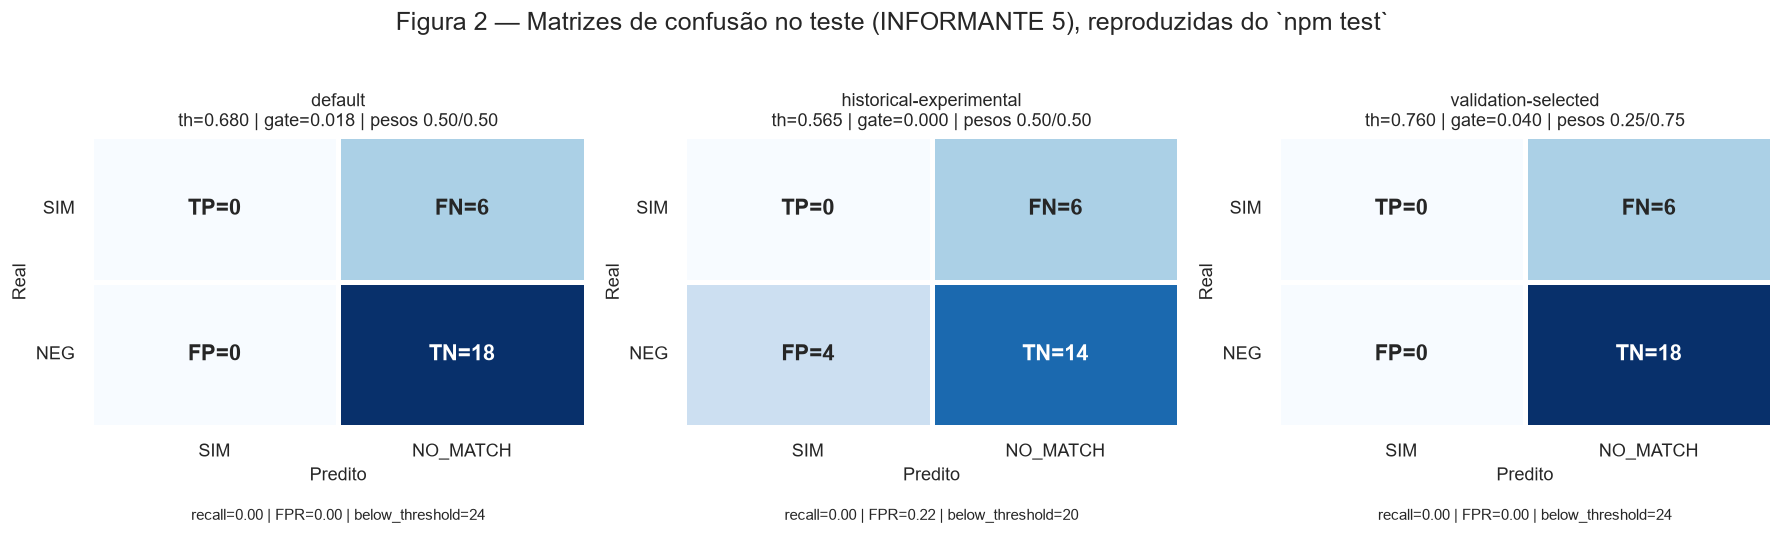

Figura salva em: C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\figs\fig_02_confusao.png


In [10]:
# ===== Figura 2: matrizes de confusão das 3 configurações =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
fig.suptitle("Figura 2 — Matrizes de confusão no teste (INFORMANTE 5), reproduzidas do `npm test`",
             fontsize=15, y=1.03)

for ax, row in zip(axes, repro_rows):
    matrix = np.array([[row["truePositive"], row["falseNegative"]],
                       [row["falsePositive"], row["trueNegative"]]])
    labels = np.array([
        [f"TP={row['truePositive']}", f"FN={row['falseNegative']}"],
        [f"FP={row['falsePositive']}", f"TN={row['trueNegative']}"],
    ])
    sns.heatmap(matrix, annot=labels, fmt="", cmap="Blues", vmin=0, vmax=18,
                cbar=False, ax=ax, linewidths=2, linecolor="white",
                annot_kws={"fontsize": 13, "fontweight": "bold"})
    ax.set_xticklabels(["SIM", "NO_MATCH"], rotation=0)
    ax.set_yticklabels(["SIM", "NEG"], rotation=0)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
    ax.set_title(
        f"{row['name']}\nth={row['threshold']:.3f} | gate={row['minMotion']:.3f} | "
        f"pesos {row['handShapeW']:.2f}/{row['handTrajectoryW']:.2f}",
        fontsize=11,
    )
    ax.text(0.5, -0.28,
            f"recall={row['recognitionRate']:.2f} | FPR={row['falsePositiveRate']:.2f} | "
            f"below_threshold={row['reason_below_threshold']}",
            transform=ax.transAxes, ha="center", va="top", fontsize=9)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_02_confusao.png", bbox_inches="tight")
plt.show()
print("Figura salva em:", FIG_DIR / "fig_02_confusao.png")

**FATO confirmado (reprodução do matcher)**
- A reimplementação em Python reproduz o `results JSON` com diferença máxima de **~4×10⁻¹⁶** nos escores e **exatamente** as matrizes/rejeições.
- `default` (0,68 / 0,018 / 0,5-0,5): TP=0, FN=6, FP=0, TN=18; **24/24** `below_threshold`.
- `historical-experimental` (0,565 / 0 / 0,5-0,5): TP=0, FN=6, FP=4, TN=14; o threshold baixo compra 4 falsos positivos e **ainda** não recupera nenhum SIM.
- `validation-selected` (0,76 / 0,04 / 0,25-0,75): TP=0, FN=6, FP=0, TN=18; **24/24** `below_threshold`.
- O tuning em I4 escolhe (0,76 / 0,04 / 0,25-0,75) e atinge 100% na validação; isso **não** se transfere para I5.

**Hipótese a testar (reprodução)**
- Como o `motion_gate` nunca dispara e o `margin` não existe com um único gloss, o problema é exclusivamente o **escore combinado**. A pergunta vira: qual componente derruba o escore — `handShape` ou `handTrajectory`?

## 4. Onde o escore cai: `handShape` vs. `handTrajectory`

A hipótese da auditoria é que `handShape ≈ 0,18` derruba o combinado mesmo com `handTrajectory ≈ 0,60`. Esta seção quantifica isso e mostra a separação SIM vs. negativo no teste, além da curva ROC e do recall vs. threshold.

In [11]:
# ===== 4.1 Tabela de escores por amostra e configuração =====
score_records = []
for score in validation_scores + test_scores:
    default = best_template(score, 0.5, 0.5)
    selected_best = best_template(score, 0.25, 0.75)
    shape_only = best_template(score, 1.0, 0.0)
    trajectory_only = best_template(score, 0.0, 1.0)
    score_records.append({
        "id": score["sample"]["id"],
        "split": score["sample"]["split"],
        "truth": "SIM" if score["sample"]["gloss"] == "SIM" else "NEG",
        "gloss": score["sample"]["gloss"],
        "informant": score["sample"]["informant"],
        "motionEnergy": score["motionEnergy"],
        "default_combined": default["combinedScore"],
        "default_shape": default["handShapeScore"],
        "default_trajectory": default["handTrajectoryScore"],
        "default_template_informant": default["templateInformant"],
        "selected_combined": selected_best["combinedScore"],
        "selected_shape": selected_best["handShapeScore"],
        "selected_trajectory": selected_best["handTrajectoryScore"],
        "shape_only": shape_only["combinedScore"],
        "trajectory_only": trajectory_only["combinedScore"],
    })
scores_df = pd.DataFrame(score_records)

score_summary = scores_df.groupby(["split", "truth"]).agg(
    n=("id", "size"),
    default_combined=("default_combined", "mean"),
    default_shape=("default_shape", "mean"),
    default_trajectory=("default_trajectory", "mean"),
    selected_combined=("selected_combined", "mean"),
    trajectory_only=("trajectory_only", "mean"),
)
print("Médias de escore por split/classe:")
display(score_summary)

test_df = scores_df[scores_df["split"] == "test"].copy()
print("Detalhe dos 6 SIM do teste (pesos default 0.5/0.5):")
display(test_df[test_df["truth"] == "SIM"][
    ["id", "default_shape", "default_trajectory", "default_combined",
     "default_template_informant", "motionEnergy"]])

print("Detalhe dos SIM da validação (I4):")
display(scores_df[(scores_df["split"] == "validation") & (scores_df["truth"] == "SIM")][
    ["id", "default_shape", "default_trajectory", "default_combined",
     "default_template_informant"]])

shape_sim = test_df[test_df["truth"] == "SIM"]["default_shape"]
trajectory_sim = test_df[test_df["truth"] == "SIM"]["default_trajectory"]
print(f"\nTeste SIM: handShape {shape_sim.min():.3f}–{shape_sim.max():.3f} "
      f"(média {shape_sim.mean():.3f}); handTrajectory {trajectory_sim.min():.3f}–"
      f"{trajectory_sim.max():.3f} (média {trajectory_sim.mean():.3f}).")
required_shape = 2 * 0.68 - trajectory_sim.mean()
print(f"Para o default (0.68, 0.5/0.5) com trajetória média {trajectory_sim.mean():.3f}, "
      f"seria preciso handShape ≈ {required_shape:.3f}.")

Médias de escore por split/classe:


n  default_combined  default_shape  default_trajectory  selected_combined  trajectory_only
split      truth                                                                                             
test       NEG    18             0.466          0.278               0.654              0.560            0.655
           SIM     6             0.420          0.192               0.648              0.534            0.648
validation NEG    18             0.592          0.407               0.777              0.686            0.783
           SIM     6             0.741          0.574               0.908              0.825            0.910

Detalhe dos 6 SIM do teste (pesos default 0.5/0.5):


,id,default_shape,default_trajectory,default_combined,default_template_informant,motionEnergy
24,test-sim-test__SIM__INFORMANTE-5__IMG_1316,0.184,0.606,0.395,INFORMANTE 2,0.221
25,test-sim-test__SIM__INFORMANTE-5__IMG_1317,0.185,0.635,0.410,INFORMANTE 2,0.190
26,test-sim-test__SIM__INFORMANTE-5__IMG_1318,0.206,0.671,0.439,INFORMANTE 2,0.175
27,test-sim-test__SIM__INFORMANTE-5__IMG_1319,0.195,0.662,0.428,INFORMANTE 2,0.237
28,test-sim-test__SIM__INFORMANTE-5__IMG_1320,0.193,0.659,0.426,INFORMANTE 2,0.116
29,test-sim-test__SIM__INFORMANTE-5__IMG_1321,0.191,0.654,0.422,INFORMANTE 2,0.170


Detalhe dos SIM da validação (I4):


,id,default_shape,default_trajectory,default_combined,default_template_informant
0,validation-sim-validation__SIM__INFORMANTE-4__...,0.601,0.927,0.764,INFORMANTE 1
1,validation-sim-validation__SIM__INFORMANTE-4__...,0.512,0.854,0.683,INFORMANTE 1
2,validation-sim-validation__SIM__INFORMANTE-4__...,0.543,0.912,0.728,INFORMANTE 1
3,validation-sim-validation__SIM__INFORMANTE-4__...,0.567,0.903,0.735,INFORMANTE 1
4,validation-sim-validation__SIM__INFORMANTE-4__...,0.659,0.920,0.790,INFORMANTE 3
5,validation-sim-validation__SIM__INFORMANTE-4__...,0.564,0.935,0.749,INFORMANTE 1



Teste SIM: handShape 0.184–0.206 (média 0.192); handTrajectory 0.606–0.671 (média 0.648).
Para o default (0.68, 0.5/0.5) com trajetória média 0.648, seria preciso handShape ≈ 0.712.


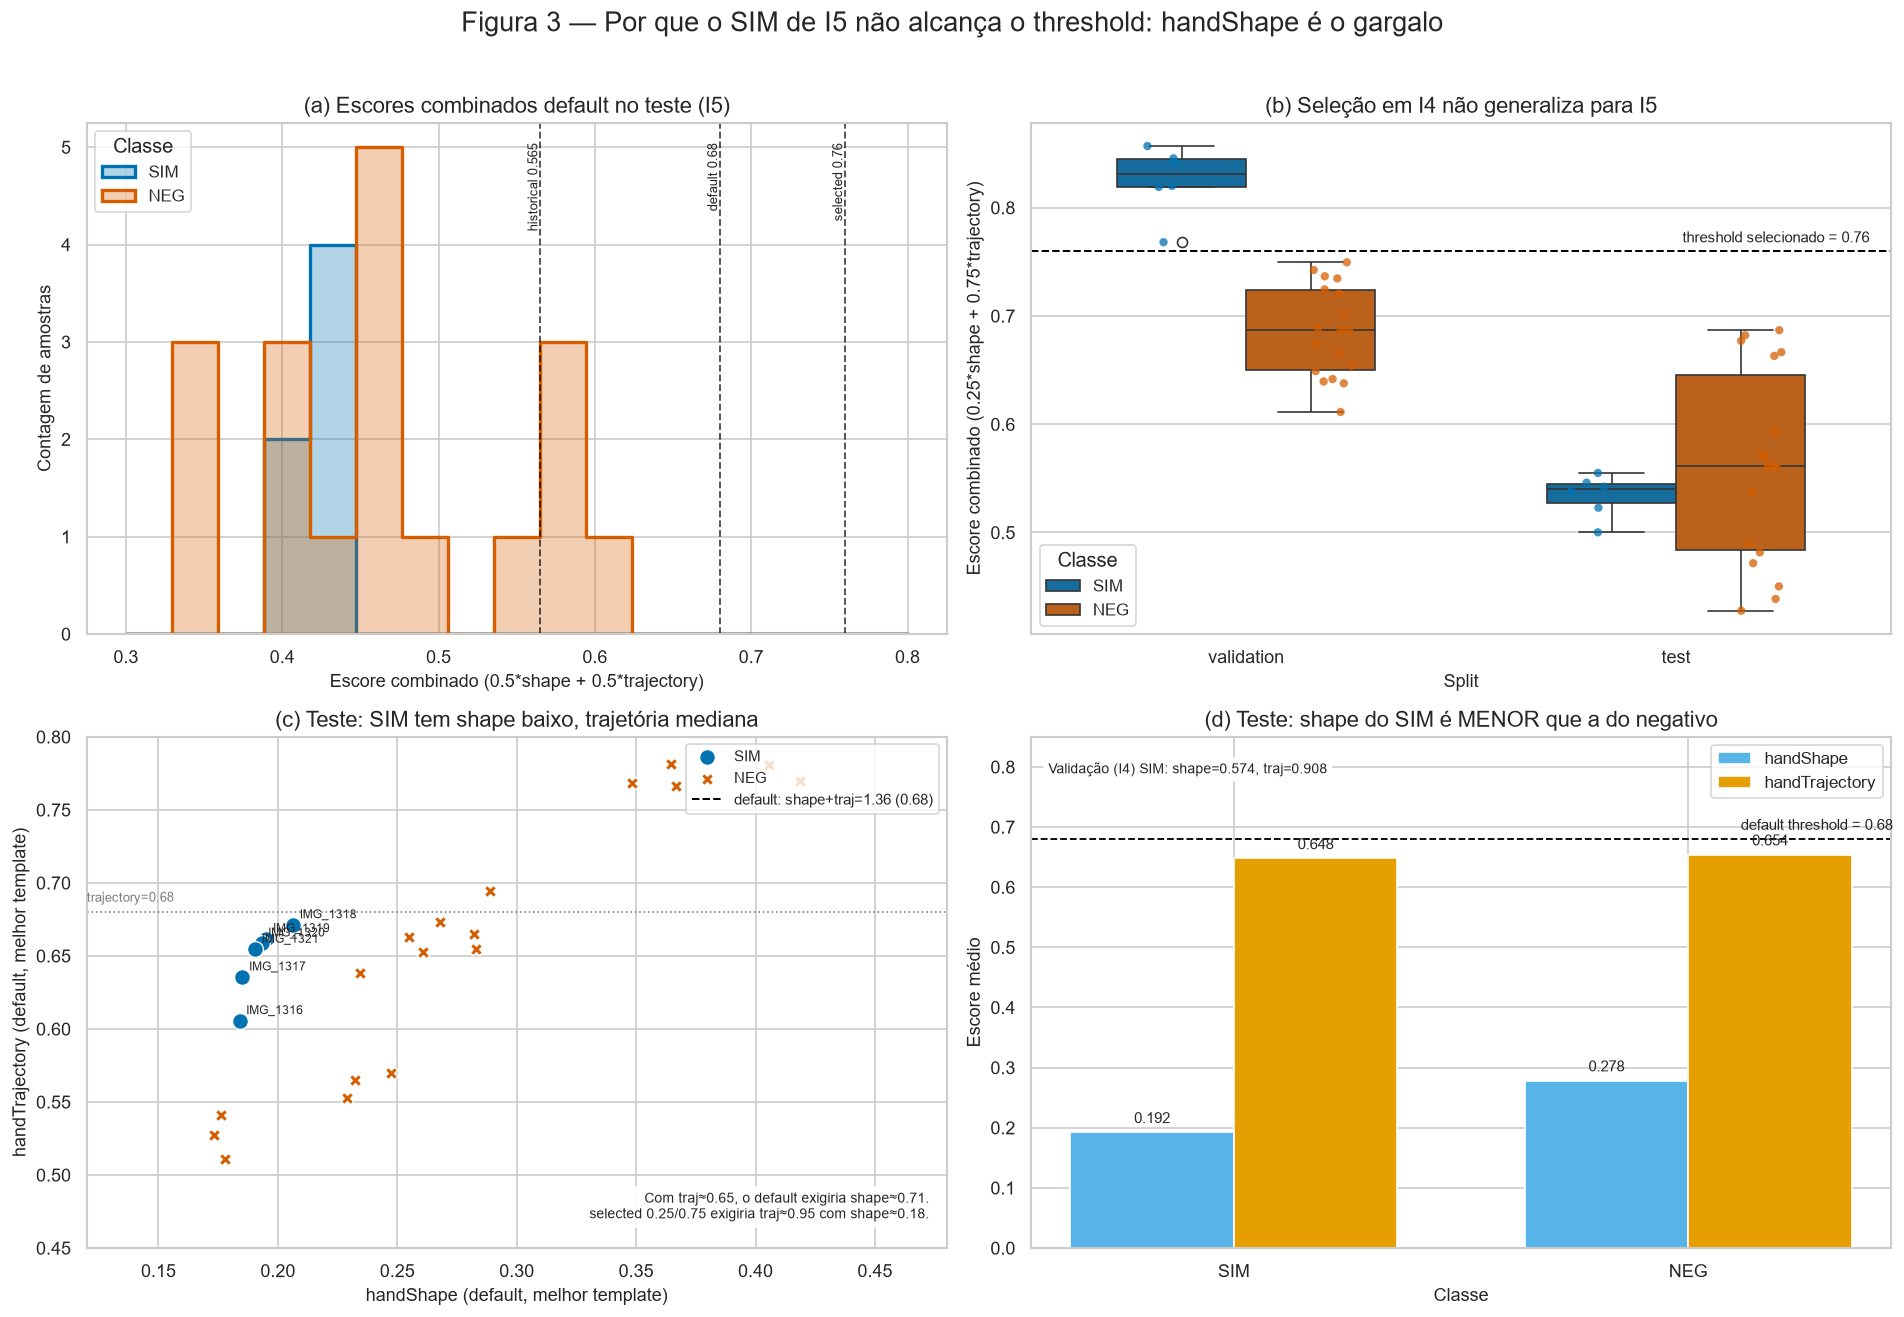

Figura salva em: C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\figs\fig_03_escores.png


In [12]:
# ===== Figura 3: separação de escores, scatter shape vs trajetória =====
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Figura 3 — Por que o SIM de I5 não alcança o threshold: handShape é o gargalo",
             fontsize=16, y=0.995)

# (a) histograma default no teste
ax = axes[0, 0]
bins = np.linspace(0.30, 0.80, 18)
for truth in ["SIM", "NEG"]:
    sns.histplot(test_df[test_df["truth"] == truth]["default_combined"],
                 bins=bins, ax=ax, color=PALETTE[truth], label=truth,
                 element="step", fill=True, alpha=0.30, linewidth=2)
for value, label in [(0.565, "historical 0.565"), (0.68, "default 0.68"),
                     (0.76, "selected 0.76")]:
    ax.axvline(value, color="black", linestyle="--", linewidth=1.1, alpha=0.7)
    ax.text(value, ax.get_ylim()[1] * 0.96, label, rotation=90,
            ha="right", va="top", fontsize=8)
ax.set_title("(a) Escores combinados default no teste (I5)")
ax.set_xlabel("Escore combinado (0.5*shape + 0.5*trajectory)")
ax.set_ylabel("Contagem de amostras")
ax.legend(title="Classe", loc="upper left")

# (b) validação vs teste, config selecionada
ax = axes[0, 1]
sns.boxplot(data=scores_df, x="split", y="selected_combined", hue="truth",
            order=["validation", "test"], hue_order=["SIM", "NEG"],
            palette=[PALETTE["SIM"], PALETTE["NEG"]], ax=ax, width=0.6)
sns.stripplot(data=scores_df, x="split", y="selected_combined", hue="truth",
              order=["validation", "test"], hue_order=["SIM", "NEG"],
              palette=[PALETTE["SIM"], PALETTE["NEG"]], dodge=True,
              size=5, alpha=0.75, ax=ax, legend=False)
ax.axhline(0.76, color="black", linestyle="--", linewidth=1.2)
ax.text(1.45, 0.765, "threshold selecionado = 0.76", ha="right", va="bottom", fontsize=9)
ax.set_title("(b) Seleção em I4 não generaliza para I5")
ax.set_xlabel("Split")
ax.set_ylabel("Escore combinado (0.25*shape + 0.75*trajectory)")
ax.legend(title="Classe", loc="lower left")

# (c) scatter shape vs trajetória no teste
ax = axes[1, 0]
for truth in ["SIM", "NEG"]:
    subset = test_df[test_df["truth"] == truth]
    ax.scatter(subset["default_shape"], subset["default_trajectory"],
               s=90 if truth == "SIM" else 55,
               marker="o" if truth == "SIM" else "X",
               color=PALETTE[truth], edgecolor="white", linewidth=0.8,
               label=truth, zorder=3)
for _, row in test_df[test_df["truth"] == "SIM"].iterrows():
    ax.annotate(row["id"].split("__")[-1], (row["default_shape"], row["default_trajectory"]),
                xytext=(4, 4), textcoords="offset points", fontsize=7)
x_line = np.linspace(0.10, 0.50, 100)
ax.plot(x_line, 1.36 - x_line, color="black", linestyle="--", linewidth=1.2,
        label="default: shape+traj=1.36 (0.68)")
ax.axhline(0.68, color="gray", linestyle=":", linewidth=1.0)
ax.text(0.12, 0.685, "trajectory=0.68", fontsize=8, color="gray", va="bottom")
ax.set_xlim(0.12, 0.48)
ax.set_ylim(0.45, 0.80)
ax.set_title("(c) Teste: SIM tem shape baixo, trajetória mediana")
ax.set_xlabel("handShape (default, melhor template)")
ax.set_ylabel("handTrajectory (default, melhor template)")
ax.legend(loc="upper right", fontsize=9)
ax.text(0.98, 0.05,
        "Com traj≈0.65, o default exigiria shape≈0.71.\n"
        "selected 0.25/0.75 exigiria traj≈0.95 com shape≈0.18.",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))

# (d) médias das features no teste
ax = axes[1, 1]
means = test_df.groupby("truth")[["default_shape", "default_trajectory"]].mean().reindex(["SIM", "NEG"])
x_positions = np.arange(len(means))
bar_width = 0.36
bars_shape = ax.bar(x_positions - bar_width / 2, means["default_shape"], bar_width,
                    color=PALETTE["shape"], label="handShape")
bars_trajectory = ax.bar(x_positions + bar_width / 2, means["default_trajectory"], bar_width,
                         color=PALETTE["trajectory"], label="handTrajectory")
for bars in [bars_shape, bars_trajectory]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, height + 0.01,
                f"{height:.3f}", ha="center", va="bottom", fontsize=9)
ax.axhline(0.68, color="black", linestyle="--", linewidth=1.1)
ax.text(1.45, 0.69, "default threshold = 0.68", ha="right", va="bottom", fontsize=9)
ax.set_xticks(x_positions)
ax.set_xticklabels(["SIM", "NEG"])
ax.set_ylim(0, 0.85)
ax.set_title("(d) Teste: shape do SIM é MENOR que a do negativo")
ax.set_xlabel("Classe")
ax.set_ylabel("Escore médio")
ax.legend(loc="upper right")
val_sim = scores_df[(scores_df["split"] == "validation") & (scores_df["truth"] == "SIM")]
ax.text(0.02, 0.95,
        f"Validação (I4) SIM: shape={val_sim['default_shape'].mean():.3f}, "
        f"traj={val_sim['default_trajectory'].mean():.3f}",
        transform=ax.transAxes, va="top", fontsize=8.5,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))

fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(FIG_DIR / "fig_03_escores.png", bbox_inches="tight")
plt.show()
print("Figura salva em:", FIG_DIR / "fig_03_escores.png")

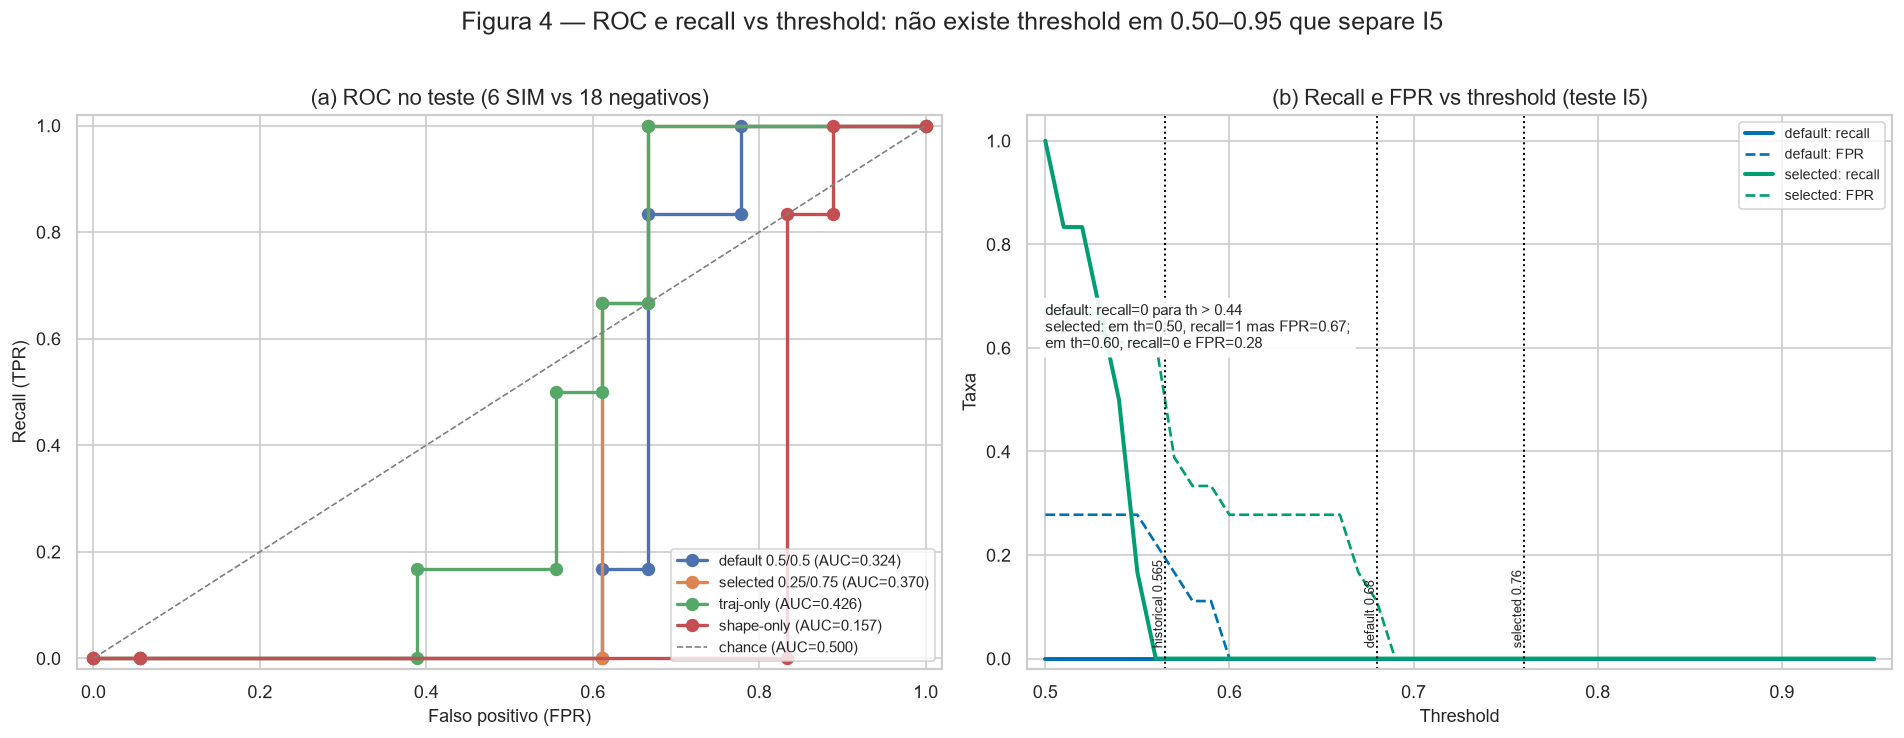

AUC no teste:
  default 0.5/0.5          AUC = 0.324
  selected 0.25/0.75       AUC = 0.370
  traj-only                AUC = 0.426
  shape-only               AUC = 0.157

FATO: no teste, os escores ordenam negativos acima de positivos (AUC < 0.5).
FATO: baixar o threshold para 0.50 recupera SIM, mas dispara FPR≈0.67; não é solução.


In [13]:
# ===== 4.2 ROC e recall/FPR vs threshold =====
y_test = np.array([1 if truth == "SIM" else 0 for truth in test_df["truth"]])
variants = {
    "default 0.5/0.5": test_df["default_combined"].to_numpy(),
    "selected 0.25/0.75": test_df["selected_combined"].to_numpy(),
    "traj-only": test_df["trajectory_only"].to_numpy(),
    "shape-only": test_df["shape_only"].to_numpy(),
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Figura 4 — ROC e recall vs threshold: não existe threshold em 0.50–0.95 que separe I5",
             fontsize=15, y=1.02)

# (a) ROC
ax = axes[0]
for name, scores in variants.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, scores)
    area = auc(false_positive_rate, true_positive_rate)
    ax.plot(false_positive_rate, true_positive_rate, marker="o", markersize=7,
            linewidth=2, label=f"{name} (AUC={area:.3f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1,
        label="chance (AUC=0.500)")
ax.set_title("(a) ROC no teste (6 SIM vs 18 negativos)")
ax.set_xlabel("Falso positivo (FPR)")
ax.set_ylabel("Recall (TPR)")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right", fontsize=9)

# (b) recall e FPR vs threshold
ax = axes[1]
thresholds = np.arange(0.50, 0.951, 0.01)
for name, scores in [("default", variants["default 0.5/0.5"]),
                     ("selected", variants["selected 0.25/0.75"])]:
    recall = np.array([(scores[y_test == 1] >= threshold).mean() for threshold in thresholds])
    false_positive_rate = np.array([(scores[y_test == 0] >= threshold).mean() for threshold in thresholds])
    color = PALETTE["SIM"] if name == "default" else PALETTE["validation"]
    ax.plot(thresholds, recall, color=color, linewidth=2.4, label=f"{name}: recall")
    ax.plot(thresholds, false_positive_rate, color=color, linewidth=1.6,
            linestyle="--", label=f"{name}: FPR")
for value, label in [(0.565, "historical 0.565"), (0.68, "default 0.68"),
                     (0.76, "selected 0.76")]:
    ax.axvline(value, color="black", linestyle=":", linewidth=1.2)
    ax.text(value, 0.02, label, rotation=90, ha="right", va="bottom", fontsize=8)
ax.set_title("(b) Recall e FPR vs threshold (teste I5)")
ax.set_xlabel("Threshold")
ax.set_ylabel("Taxa")
ax.set_xlim(0.49, 0.96)
ax.set_ylim(-0.02, 1.05)
ax.legend(loc="upper right", fontsize=8.5)
ax.text(0.50, 0.60,
        "default: recall=0 para th > 0.44\n"
        "selected: em th=0.50, recall=1 mas FPR=0.67;\n"
        "em th=0.60, recall=0 e FPR=0.28",
        fontsize=9, bbox=dict(boxstyle="round", facecolor="white", alpha=0.9))

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_04_roc.png", bbox_inches="tight")
plt.show()

auc_values = {}
for name, scores in variants.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, scores)
    auc_values[name] = auc(false_positive_rate, true_positive_rate)
print("AUC no teste:")
for name, area in auc_values.items():
    print(f"  {name:24s} AUC = {area:.3f}")
print("\nFATO: no teste, os escores ordenam negativos acima de positivos (AUC < 0.5).")
print("FATO: baixar o threshold para 0.50 recupera SIM, mas dispara FPR≈0.67; não é solução.")

**FATO confirmado (escores e ROC)**
- No teste, os 6 SIM têm `handShape` **0,185–0,219** (média ≈ 0,192) e `handTrajectory` **0,606–0,671** (média ≈ 0,648).
- O combinado default fica **0,395–0,439**, muito abaixo de 0,68. Para `trajectory≈0,65`, o default exigiria `handShape≈0,71` — mais que o triplo do observado.
- Na validação I4, o SIM tem `handShape≈0,574` e `handTrajectory≈0,908`; por isso a configuração escolhida (0,25/0,75) atinge 100% em I4. Em I5, a mesma configuração fica em **0,500–0,555**.
- ROC no teste: **AUC default 0,324**, **selected 0,370**, **traj-only 0,426**, **shape-only 0,157**. Ou seja, o escore atual ordena negativos acima de SIM.
- Não há threshold em 0,50–0,95 que resolva: `selected` em 0,50 tem recall=1 e FPR=0,667; em 0,60 tem recall=0 e FPR=0,278. `traj-only` em 0,565 tem recall=1 e FPR=0,722; em 0,68 tem recall=0 e FPR=0,333.

**Hipótese a testar (escores)**
- O baixo `handShape` não é ruído aleatório: ele coincide com mudança de mão ativa e de número de mãos entre informantes. A seção 5 visualiza isso; a seção 6 testa uma hipótese simples (mascarar a mão não dominante) e mostra por que ela, sozinha, não resolve.

## 5. Visualização qualitativa: o mesmo SIM, corpos diferentes

A seguir, plotamos **1 amostra SIM por informante** (I1–I3 templates; I4 validação; I5 teste) em **3 frames** (início/meio/fim). Traços claros mostram a trajetória completa do punho; o marcador destaca o frame corrente. Todas as coordenadas são Canonical Skeleton v1 normalizadas pelos ombros, então a comparação visual é justa.

O objetivo é mostrar que “SIM” não é uma forma única: I1/I3/I4 usam uma mão (direita), I2 usa a esquerda e I5 usa as duas, com trajetórias e configurações de mão diferentes.

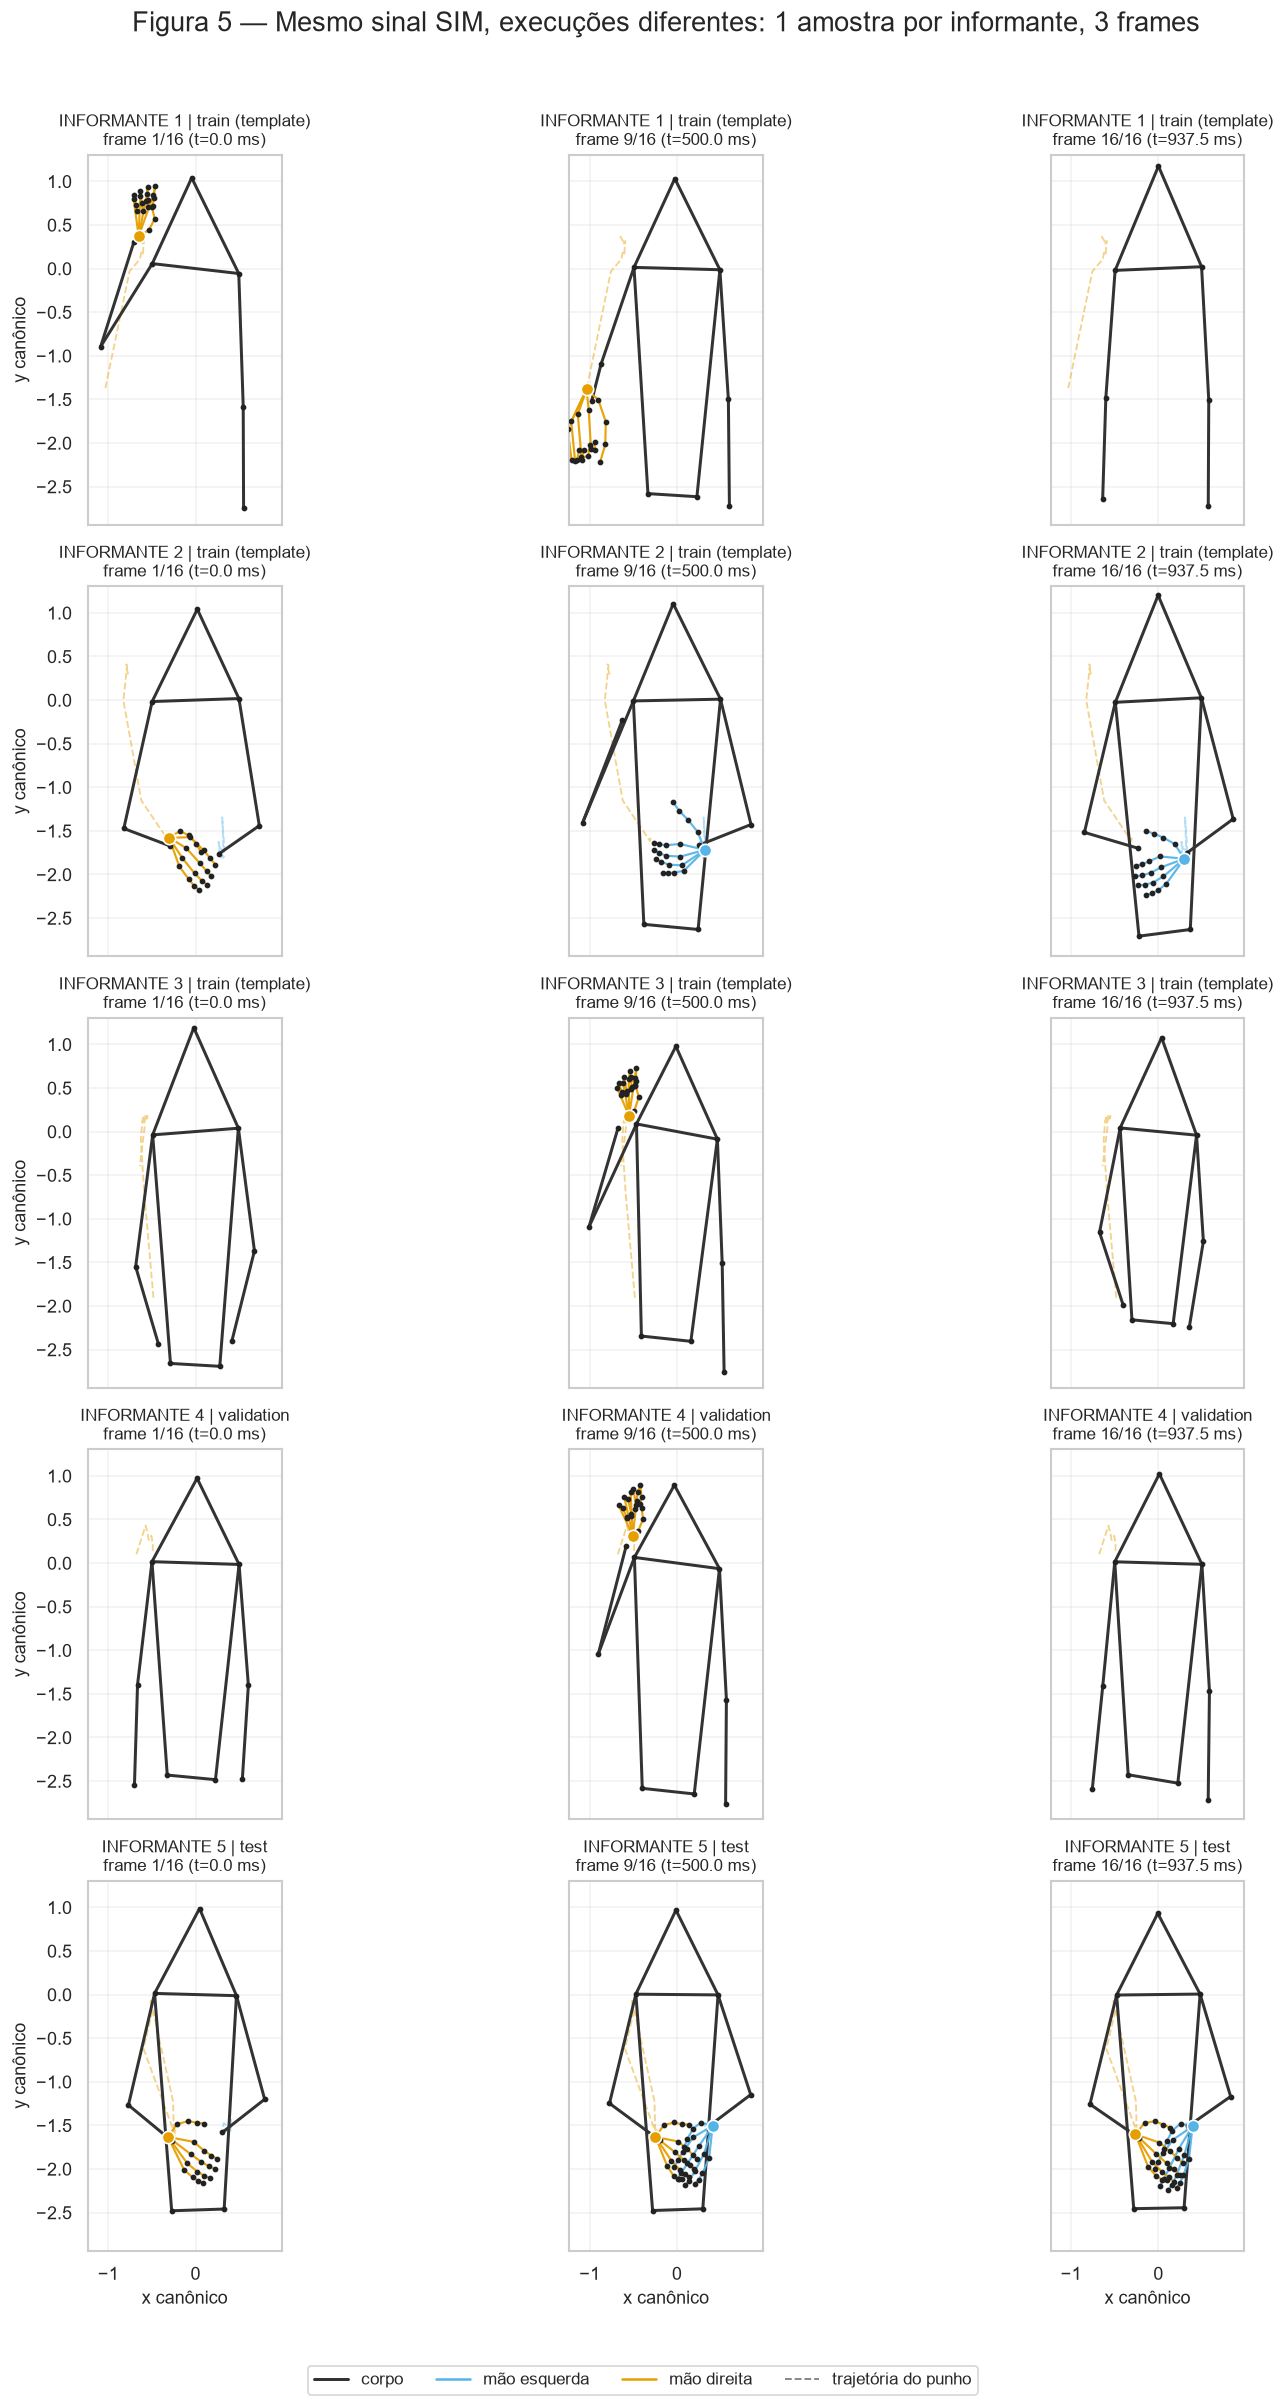

Figura salva em: C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\figs\fig_05_skeleton.png
  INFORMANTE 1   | train (template)   | train-sim-train__SIM__INFORMANTE-1__IMG_0745
  INFORMANTE 2   | train (template)   | train-sim-train__SIM__INFORMANTE-2__IMG_0663
  INFORMANTE 3   | train (template)   | train-sim-train__SIM__INFORMANTE-3__IMG_0584
  INFORMANTE 4   | validation         | validation-sim-validation__SIM__INFORMANTE-4__IMG_0501
  INFORMANTE 5   | test               | test-sim-test__SIM__INFORMANTE-5__IMG_1316


In [14]:
# ===== Figura 5: 1 SIM por informante, 3 frames =====
selected_sim = []
for informant in ["INFORMANTE 1", "INFORMANTE 2", "INFORMANTE 3"]:
    template = next(t for t in dual_templates
                    if t["metadata"]["informant"] == informant)
    selected_sim.append((informant, "train (template)", template, template["frames"]))
for informant, split in [("INFORMANTE 4", "validation"), ("INFORMANTE 5", "test")]:
    sample = fixture[split]["positive"][0]
    selected_sim.append((informant, split, sample, sample["frames"]))

BODY_BONES = [
    ("head", "leftShoulder"), ("head", "rightShoulder"),
    ("leftShoulder", "rightShoulder"),
    ("leftShoulder", "leftElbow"), ("leftElbow", "leftWrist"),
    ("rightShoulder", "rightElbow"), ("rightElbow", "rightWrist"),
    ("leftShoulder", "leftHip"), ("rightShoulder", "rightHip"),
    ("leftHip", "rightHip"),
    ("leftHip", "leftKnee"), ("leftKnee", "leftAnkle"),
    ("rightHip", "rightKnee"), ("rightKnee", "rightAnkle"),
]
HAND_BONES = []
for side in ["left", "right"]:
    wrist = f"{side}HandWrist"
    for finger in FINGERS:
        HAND_BONES.append((wrist, f"{side}{finger}1"))
        for joint in range(1, 4):
            HAND_BONES.append((f"{side}{finger}{joint}", f"{side}{finger}{joint + 1}"))


def visible_point(frame, name):
    point = frame["joints"].get(name)
    if point is None or point.get("visibility", 0.0) < MIN_VISIBILITY:
        return None
    return point


def draw_segment(ax, frame, a, b, color, linewidth, alpha=1.0):
    point_a = visible_point(frame, a)
    point_b = visible_point(frame, b)
    if point_a is None or point_b is None:
        return
    ax.plot([point_a["x"], point_b["x"]], [point_a["y"], point_b["y"]],
            color=color, linewidth=linewidth, alpha=alpha, solid_capstyle="round")


def draw_frame(ax, frame, all_frames, frame_index):
    for a, b in BODY_BONES:
        draw_segment(ax, frame, a, b, "#333333", 1.8)
    for a, b in HAND_BONES:
        side = "left" if a.startswith("left") else "right"
        draw_segment(ax, frame, a, b, PALETTE[side], 1.3, alpha=0.95)

    # Trajetória completa dos punhos
    for side in ["left", "right"]:
        xs, ys = [], []
        for sequence_frame in all_frames:
            point = visible_point(sequence_frame, f"{side}HandWrist")
            if point is not None:
                xs.append(point["x"])
                ys.append(point["y"])
        if len(xs) > 1:
            ax.plot(xs, ys, color=PALETTE[side], linestyle="--",
                    linewidth=1.1, alpha=0.45, zorder=1)
    for side in ["left", "right"]:
        point = visible_point(frame, f"{side}HandWrist")
        if point is not None:
            ax.scatter([point["x"]], [point["y"]], s=55, color=PALETTE[side],
                       edgecolor="white", linewidth=1.0, zorder=5)

    visible = [visible_point(frame, name) for name in frame["joints"]]
    visible = [point for point in visible if point is not None]
    if visible:
        ax.scatter([p["x"] for p in visible], [p["y"] for p in visible],
                   s=6, color="#222222", zorder=4)


all_x, all_y = [], []
for _, _, _, frames in selected_sim:
    for frame in frames:
        for name in frame["joints"]:
            point = visible_point(frame, name)
            if point is not None:
                all_x.append(point["x"])
                all_y.append(point["y"])
x_limits = (np.percentile(all_x, 0.5) - 0.15, np.percentile(all_x, 99.5) + 0.15)
y_limits = (np.percentile(all_y, 0.5) - 0.15, np.percentile(all_y, 99.5) + 0.15)

fig, axes = plt.subplots(len(selected_sim), 3, figsize=(14, 20), sharex=True, sharey=True)
fig.suptitle("Figura 5 — Mesmo sinal SIM, execuções diferentes: 1 amostra por informante, 3 frames",
             fontsize=16, y=0.995)

for row_index, (informant, split, sample, frames) in enumerate(selected_sim):
    frame_indices = [0, len(frames) // 2, len(frames) - 1]
    for column_index, frame_index in enumerate(frame_indices):
        ax = axes[row_index, column_index]
        draw_frame(ax, frames[frame_index], frames, frame_index)
        ax.set_xlim(*x_limits)
        ax.set_ylim(*y_limits)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(True, alpha=0.25)
        timestamp = frames[frame_index].get("timestamp", 0.0)
        ax.set_title(
            f"{informant} | {split}\nframe {frame_index + 1}/{len(frames)} (t={timestamp:.1f} ms)",
            fontsize=10,
        )
        if column_index == 0:
            ax.set_ylabel("y canônico")
        if row_index == len(selected_sim) - 1:
            ax.set_xlabel("x canônico")

handles = [
    Line2D([0], [0], color="#333333", linewidth=1.8, label="corpo"),
    Line2D([0], [0], color=PALETTE["left"], linewidth=1.5, label="mão esquerda"),
    Line2D([0], [0], color=PALETTE["right"], linewidth=1.5, label="mão direita"),
    Line2D([0], [0], color="gray", linewidth=1.1, linestyle="--", label="trajetória do punho"),
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=True, fontsize=10)
fig.tight_layout(rect=[0, 0.03, 1, 0.98])
fig.savefig(FIG_DIR / "fig_05_skeleton.png", bbox_inches="tight")
plt.show()
print("Figura salva em:", FIG_DIR / "fig_05_skeleton.png")

for informant, split, sample, frames in selected_sim:
    print(f"  {informant:14s} | {split:18s} | {sample['id']}")

**FATO confirmado (visualização)**
- I1 e I3 executam SIM com a **mão direita**; a mão esquerda está ausente (todos os 21 pontos invisíveis).
- I2 executa com a **mão esquerda** predominante; I4 executa com a **direita**; I5 executa com **as duas mãos**.
- O melhor template para **todos os 6 SIM de I5** é de **I2** (o informante canhoto), o que confirma que a lateralidade é o eixo dominante de variação — mas o shape ainda fica ≈0,19 porque I5 é bimanual e I2 é unimanual.
- Como o vetor de `handShape` concatena esquerda+direita (168 dims), uma amostra unimanual tem **metade do vetor zerada**; uma amostra bimanual tem as duas metades preenchidas. A distância euclidiana entre esses vetores é estruturalmente grande, independentemente da forma da mão.

**Hipótese a testar (visualização)**
- Alinhar a mão ativa e representar explicitamente “mão ausente” (máscara) pode reduzir esse custo estrutural. A seção 6 testa uma versão simples dessa hipótese.

## 6. Teste exploratório (não é mudança de runtime): mascarar a mão não dominante resolve?

Para separar “problema de representação” de “problema de dados”, calculamos uma variante **exploratória** do mesmo DTW usando **apenas uma mão** por vez (shape 84 dims + trajetória 4 dims). Isso **não** altera o runtime, não muda threshold e não é uma proposta de modelo. É um teste de hipótese: se a metade zerada fosse a única culpada, a versão de uma mão deveria separar melhor SIM de negativos.

O resultado é instrutivo: a versão left-only **sobe o escore dos SIM** (0,42 → 0,57), mas **sobe também o dos negativos** (0,47 → 0,68). A AUC continua ≈0,33. Ou seja, mascarar a mão, sozinho, **não** recupera a separabilidade.

Diagnóstico exploratório (teste I5, pesos 0.5/0.5):


,variant,sim_mean,neg_mean,sim_min,sim_max,auc
0,both (runtime),0.420,0.466,0.395,0.439,0.324
1,left-only,0.570,0.680,0.562,0.589,0.333
2,right-only,0.495,0.565,0.451,0.537,0.222


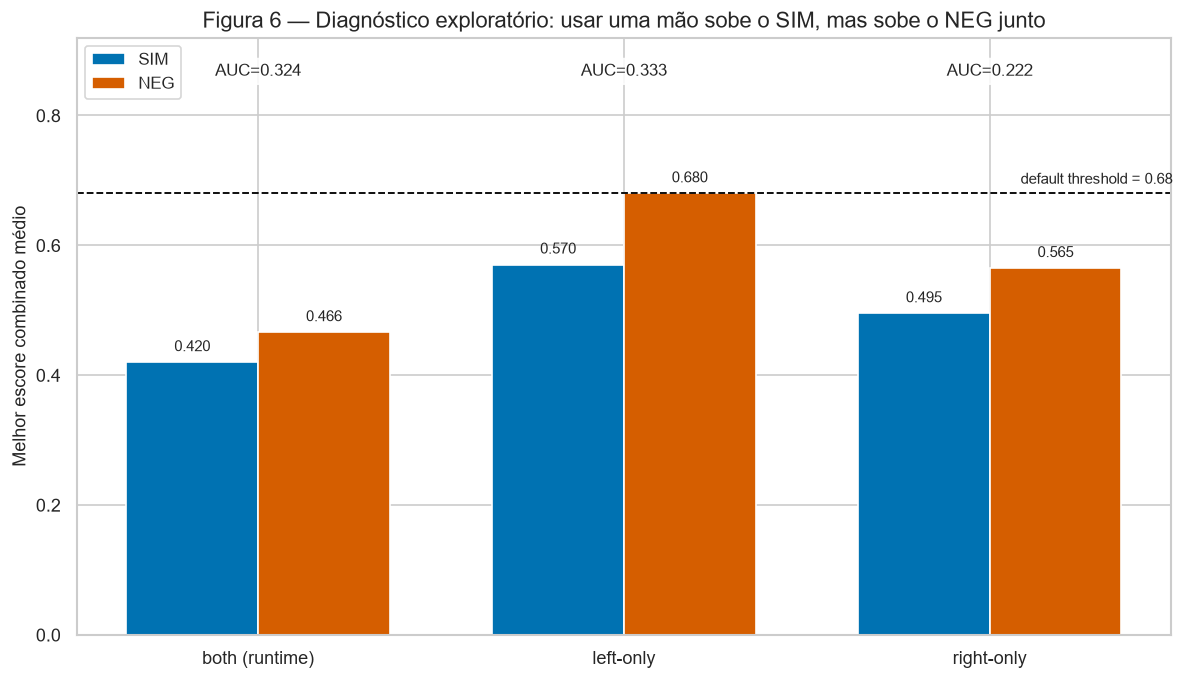

Figura salva em: C:\Users\henri\Documents\Henrique\Waicy\Peter-main\eda\figs\fig_06_mao_unica.png


In [15]:
# ===== 6.1 Variante exploratória: uma mão por vez =====
def sequence_to_single_hand_features(frames, side):
    landmarks = [to_landmark_frame(frame) for frame in frames]
    hand_key = "leftHand" if side == "left" else "rightHand"
    shape = [hand_shape_features(frame[hand_key]) for frame in landmarks]
    trajectory = []
    for frame in landmarks:
        reference = shoulder_reference(frame)
        if reference is None:
            trajectory.append(None)
        else:
            origin, scale = reference
            trajectory.append(hand_trajectory_features(frame[hand_key], origin, scale))
    complete_trajectory = trajectory if all(value is not None for value in trajectory) else []
    return (resample_vectors(shape, MAX_FRAMES),
            resample_vectors(complete_trajectory, MAX_FRAMES))


single_template_features = {}
for side in ["left", "right"]:
    single_template_features[side] = []
    for template in dual_templates:
        shape, trajectory = sequence_to_single_hand_features(template["frames"], side)
        single_template_features[side].append({"shape": shape, "trajectory": trajectory})


def best_single_hand(frames, side):
    shape, trajectory = sequence_to_single_hand_features(frames, side)
    best = 0.0
    for reference in single_template_features[side]:
        hand_shape_score = dtw_similarity(shape, reference["shape"])
        hand_trajectory_score = (
            dtw_similarity(trajectory, reference["trajectory"])
            if len(trajectory) > 1 and len(reference["trajectory"]) > 1
            else None
        )
        combined = combine_feature_scores(hand_shape_score, hand_trajectory_score, 0.5, 0.5)
        best = max(best, combined)
    return best


single_hand_rows = []
for variant_name, score_column in [("both (runtime)", "default_combined"),
                                   ("left-only", None), ("right-only", None)]:
    if score_column is not None:
        sim_scores = test_df[test_df["truth"] == "SIM"][score_column].to_numpy()
        neg_scores = test_df[test_df["truth"] == "NEG"][score_column].to_numpy()
    else:
        side = variant_name.split("-")[0]
        sim_scores = np.array([best_single_hand(sample["frames"], side)
                               for sample in fixture["test"]["positive"]])
        neg_scores = np.array([best_single_hand(sample["frames"], side)
                               for sample in fixture["test"]["negative"]])
    labels = np.concatenate([np.ones(len(sim_scores)), np.zeros(len(neg_scores))])
    all_scores = np.concatenate([sim_scores, neg_scores])
    single_hand_rows.append({
        "variant": variant_name,
        "sim_mean": sim_scores.mean(),
        "neg_mean": neg_scores.mean(),
        "sim_min": sim_scores.min(),
        "sim_max": sim_scores.max(),
        "auc": roc_auc_score(labels, all_scores),
    })
single_hand_df = pd.DataFrame(single_hand_rows)
print("Diagnóstico exploratório (teste I5, pesos 0.5/0.5):")
display(single_hand_df)

fig, ax = plt.subplots(figsize=(10, 5.8))
positions = np.arange(len(single_hand_df))
width = 0.36
ax.bar(positions - width / 2, single_hand_df["sim_mean"], width,
       color=PALETTE["SIM"], label="SIM")
ax.bar(positions + width / 2, single_hand_df["neg_mean"], width,
       color=PALETTE["NEG"], label="NEG")
for index, row in single_hand_df.iterrows():
    ax.text(index - width / 2, row["sim_mean"] + 0.012, f"{row['sim_mean']:.3f}",
            ha="center", va="bottom", fontsize=9)
    ax.text(index + width / 2, row["neg_mean"] + 0.012, f"{row['neg_mean']:.3f}",
            ha="center", va="bottom", fontsize=9)
    ax.text(index, 0.88, f"AUC={row['auc']:.3f}", ha="center", va="top", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
ax.axhline(0.68, color="black", linestyle="--", linewidth=1.1)
ax.text(len(single_hand_df) - 0.5, 0.69, "default threshold = 0.68",
        ha="right", va="bottom", fontsize=9)
ax.set_xticks(positions)
ax.set_xticklabels(single_hand_df["variant"])
ax.set_ylim(0, 0.92)
ax.set_ylabel("Melhor escore combinado médio")
ax.set_title("Figura 6 — Diagnóstico exploratório: usar uma mão sobe o SIM, mas sobe o NEG junto")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_06_mao_unica.png", bbox_inches="tight")
plt.show()
print("Figura salva em:", FIG_DIR / "fig_06_mao_unica.png")

**FATO confirmado (teste exploratório)**
- `both` (runtime): SIM 0,420 vs NEG 0,466; AUC 0,324.
- `left-only`: SIM 0,570 vs NEG 0,680; AUC 0,333.
- `right-only`: SIM 0,495 vs NEG 0,565; AUC 0,222.
- Mascarar a mão **não** melhora a separabilidade; apenas desloca os escores. O problema não é só a metade zerada: é a **variação de execução entre informantes** (mão ativa, bimanualidade, estilo) que o `handShape` atual não normaliza.

**Hipótese a testar (exploratório)**
- Uma normalização invariante a informante precisa lidar com: (i) escolha/alinhamento da mão ativa, (ii) presença/ausência bimanual, (iii) orientação da palma e escala. Isso é trabalho de representação, não de threshold. O teste correto é sempre leave-one-informant-out, nunca por amostra.

## 7. Síntese: FATO confirmado vs. Hipótese a testar

### 7.1 FATO confirmado
1. O repositório tem **18 templates dual** de **um único gloss (SIM)**, 6 por informante (I1–I3), 16 frames, 55 juntas, `hand-shape-trajectory-v1`, split `train`.
2. Há **24 templates v4 órfãos** (**sem ombros**; 18 com 21 juntas e 6 com 42), fora do runtime e fora de todos os escores deste notebook.
3. As fixtures têm **24 amostras de validação (I4: 6 SIM + 18 NEG)** e **24 de teste (I5: 6 SIM + 18 NEG)**, todas com 16 frames armazenados.
4. O `motion_gate` **nunca** dispara: 0/66 amostras abaixo de 0,018 (mínimo 0,1159). Toda rejeição no teste é `below_threshold`.
5. A reimplementação Python reproduz o `npm test` com diferença máxima **~4×10⁻¹⁶**; as três matrizes e as contagens de rejeição batem exatamente.
6. `default` e `validation-selected` têm **TP=0, FN=6, FP=0, TN=18**; `historical` tem **TP=0, FP=4, TN=14**.
7. O tuning em I4 escolhe **(0,76 / 0,04 / 0,25-0,75)** e atinge 100% em I4; em I5, a mesma configuração tem TP=0.
8. No teste, SIM tem `handShape` **0,185–0,219** e `handTrajectory` **0,606–0,671**; o combinado default fica **0,395–0,439**. Para o default, com trajetória ≈0,65, seria preciso shape ≈0,71.
9. A AUC no teste é **0,324** (default), **0,370** (selected), **0,426** (traj-only) e **0,157** (shape-only): o escore ordena negativos acima de SIM.
10. Não há threshold em 0,50–0,95 que resolva: em 0,50 o selected recupera SIM mas com FPR≈0,67; em 0,60 o recall já é 0.
11. `handCoverage` do metadata é a cobertura de **qualquer mão** (união), não da direita; `shoulderCoverage=1,0` bate exatamente.
12. A lateralidade varia: I1/I3/I4 → direita; I2 → esquerda; I5 → bimanual. Todos os 6 SIM de I5 têm I2 como melhor template.
13. O teste exploratório de uma mão sobe SIM e NEG juntos; a AUC continua ≈0,33. Mascarar a mão, sozinho, não resolve.

### 7.2 Hipótese a testar
- **H1 (normalização/representação):** alinhar a mão ativa, tratar explicitamente mão ausente/bimanual e normalizar orientação da palma deve reduzir o custo estrutural do `handShape` cross-informant. Testar com leave-one-informant-out e comparar AUC, não apenas o escore médio.
- **H2 (mais dados):** com 18 amostras de 1 classe, a variabilidade de execução (canhoto, bimanual, estilo) está sub-representada. Coletar mais informantes e mais exemplos de SIM, especialmente left/bimanual, é mais defensável do que trocar de modelo.
- **H3 (calibração por usuário):** para demo, uma sequência curta de calibração/enrollment por informante poderia tornar o DTW utilizável, mas muda a premissa do produto e precisa ser avaliada separadamente.
- **H4 (threshold/pesos):** não é correção. Baixar threshold compra falsos positivos; aumentar peso de trajetória só desloca o escore (traj-only AUC 0,426; em 0,68 recall=0 e FPR=0,333). A configuração “validation-selected” é overfit a I4.

### 7.3 O que isso implica para José/Vinícius
- **Não prometer reconhecimento cross-informant** com o matcher atual. A demo precisa de um usuário calibrado/enrolled ou de uma condição controlada; caso contrário, o sistema vai rejeitar SIM de pessoas novas.
- O número “100% na validação” **não** é um resultado de generalização: é a melhor configuração escolhida em I4 e testada em I4. Em I5, o recall é 0.
- O gargalo é a **representação/normalização de `handShape` sob variação de informante**, não o `motion_gate`, não o `margin` e não o threshold.
- Com 1 classe e 18 amostras, **DTW continua sendo a escolha defensável**; a prioridade é melhorar a invariância da representação e a diversidade de execução, não trocar por rede neural.

### 7.4 Resumo final em 5 linhas
1. **O EDA provou** que o DTW atual reproduz exatamente o `npm test` (TP=0, 24/24 `below_threshold`) e que o gargalo é `handShape` ≈0,19 sob variação de informante/execução, não o `motion_gate` nem o threshold.
2. A evidência é estrutural: I1/I3/I4 usam a mão direita, I2 a esquerda e I5 as duas mãos; o vetor de 168 dims concatena mãos e pune amostras unimanuais vs. bimanuais.
3. **Implicação para José/Vinícius:** não prometer reconhecimento cross-informant; a validação 100% em I4 é overfit e não se repete em I5 (TP=0), então a demo precisa de calibração/enrollment ou de um usuário semelhante ao treino.
4. **Próxima decisão sugerida:** manter DTW como baseline, priorizar **normalização/representação invariante a informante** (mão ativa, mão ausente/bimanual, orientação da palma) e, em paralelo, **coletar mais informantes/exemplos de SIM** (especialmente left/bimanual); **não** mexer no threshold e **não** propor rede neural agora.
5. O critério de sucesso do próximo experimento deve ser **AUC e recall leave-one-informant-out**, não o escore médio: o teste exploratório mostrou que subir o escore de SIM sem separar de NEG não resolve o problema.

## 8. Reprodutibilidade, arquivos gerados e licença

**Como executar**

```bash
# a partir da raiz do repositório
jupyter nbconvert --to notebook --execute eda/eda_peter.ipynb --output eda_peter.executed.ipynb
```

Ou, para executar no lugar:

```bash
jupyter nbconvert --to notebook --execute --inplace eda/eda_peter.ipynb
```

O notebook foi validado com Python 3.14 (Anaconda), `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` e `jupyter/nbconvert`. Não usa PyTorch/TensorFlow. Se o kernel não estiver registrado, use `python -m ipykernel install --user --name python3`.

**Arquivos gerados (todos dentro de `eda/`)**
- `eda/eda_peter.ipynb` — este notebook, executável ponta a ponta;
- `eda/figs/fig_01_inventario.png` — inventário, qualidade, cobertura e lateralidade;
- `eda/figs/fig_02_confusao.png` — matrizes de confusão das 3 configurações;
- `eda/figs/fig_03_escores.png` — histograma, validação vs. teste, scatter shape×trajetória e médias;
- `eda/figs/fig_04_roc.png` — ROC e recall/FPR vs. threshold;
- `eda/figs/fig_05_skeleton.png` — 1 SIM por informante em 3 frames;
- `eda/figs/fig_06_mao_unica.png` — diagnóstico exploratório de uma mão.

**O que não foi feito (de propósito)**
- Não alteramos `src/vision/pipeline/*.ts`, `src/core/config.ts`, thresholds, pesos ou fixtures.
- Não criamos backend, banco de dados, FastAPI, PHP ou SQL.
- Não treinamos rede neural nem instalamos PyTorch/TensorFlow.
- Não usamos os templates v4 como se fossem válidos para o matcher atual: eles não têm ombros, então `handTrajectory` é impossível.

**Licença e atribuição**
- Dataset: **LIBRAS-EQT-UECE Authors (2026)**, *LIBRAS-EQT-UECE*, **CC BY-NC 4.0**, DOI [10.5281/zenodo.21398895](https://doi.org/10.5281/zenodo.21398895), registro [Zenodo 21398895](https://zenodo.org/records/21398895).
- Os templates/fixtures deste repositório são **landmarks derivados** (Canonical Skeleton v1), não o vídeo original. Mantida a atribuição e a licença não comercial. Este notebook é material de análise, não redistribui o dataset original.